# Map plots of equation terms between ERA5 and historical simulations
This Notebook permits to plot the extreme exceedance in the historical period of regional simulations and ERA5 and the difference between both. It also shows the contribution of each three terms of the equation to highlight which one is driving the change of extreme exceedance.

In [1]:
import xarray as xr
import pickle
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy
from mpl_toolkits.axes_grid1 import make_axes_locatable
import numpy as np
from scipy.ndimage import gaussian_filter
import matplotlib.colors as mcolors
import matplotlib
from matplotlib.ticker import FuncFormatter

# Loading Data

In [2]:
# Tropical cyclone filter of the cyclone-related inputs (see ETC_tools.py): None (all
# cyclones, as in the submitted version), 'phase' (only the extratropical time steps)
# or 'storm' (no cyclone with a tropical phase). The percentiles do not depend on it.
tc_filter = 'phase'
tc_tag = {None: '', 'phase': '_noTC', 'storm': '_noTCstorm'}[tc_filter]

simulations = ['ERA5', 'UBB', 'UBD', 'UBE', 'UBF']

ds_dens = {}
per_regridded = {}

for sim in simulations:
    for var in ['pr', 'ws']:
        if var == 'pr':
            if sim == 'ERA5':
                percentile_path = f'/home/vdemeyer/projects/rrg-gachon/vdemeyer/{sim}/PR_Percentile/pr_{sim.lower()}_percentile_1980-2014.nc'
            else:
                percentile_path = f'/home/vdemeyer/projects/rrg-gachon/vdemeyer/{sim}/PR_Percentile/pr_{sim.lower()}_percentile_1980-2014_regridded_on_ERA5.nc'
        else:
            if sim == 'ERA5':
                percentile_path = f'/home/vdemeyer/projects/rrg-gachon/vdemeyer/{sim}/WIND_Percentile/surf_wind_{sim.lower()}_percentile_1980-2014.nc'
            else:
                percentile_path = f'/home/vdemeyer/projects/rrg-gachon/vdemeyer/{sim}/WIND_Percentile/surf_wind_{sim.lower()}_percentile_1980-2014_regridded_on_ERA5.nc'

        per_regridded[(sim, var)] = xr.open_dataset(percentile_path)

    add_regrid = '_regridded_on_ERA5' if sim != 'ERA5' else ''
    file = f"/project/rrg-gachon/vdemeyer/{sim}/STORM_RELATED/DENSITY/density_ETCs_center_{sim.lower()}_all_seasons{tc_tag}{add_regrid}.nc"
    ds = xr.open_dataset(file)
    ds_dens[sim] = ds

In [3]:
file_path = f'/home/vdemeyer/projects/rrg-gachon/vdemeyer/ALL/CONTRIB/contribution_ETCs_1000hPa{tc_tag}_regridded_on_ERA5.pkl'

with open(file_path, 'rb') as file:
    data = pickle.load(file)

# Map plots

## Function to plot the maps

In [4]:
mask = data['total_total']['UBB'].sel(variable='ws') > 0

sim_label = {
    'ERA5': r'ERA5',
    'UBB': r'CRCM6$_{\mathbf{ERA5}}$',
    'UBD': r'CRCM6$_{\mathbf{EC\text{-}Earth3\text{-}Veg}}$',
    'UBE': r'CRCM6$_{\mathbf{MPI\text{-}ESM1\text{-}2\text{-}HR}}$',
    'UBF': r'CRCM6$_{\mathbf{MIROC6}}$'
}

sim_label_nobold = {
    'ERA5': r'ERA5',
    'UBB': r'CRCM6$_{\mathrm{ERA5}}$',
    'UBD': r'CRCM6$_{\mathrm{EC\text{-}Earth3\text{-}Veg}}$',
    'UBE': r'CRCM6$_{\mathrm{MPI\text{-}ESM1\text{-}2\text{-}HR}}$',
    'UBF': r'CRCM6$_{\mathrm{MIROC6}}$'
}

def clean_float(x, pos):
    """Formateur pour retirer les notations scientifiques pour les petits nombres."""
    if abs(x) < 1e-8: # seuil de tolérance (adjustable)
        x = 0
    return '%g' % x

def get_colormap(colormap_name, style=None, rework=True):
    """
    Récupère une colormap, avec une modification spéciale pour 'Spectral_r'.
    (Fonction inchangée)
    """
    # Si l'entrée est déjà une colormap (comme cmocean.cm.curl)
    if hasattr(colormap_name, '__call__'):
        return colormap_name

    # Cas spécial pour 'Spectral_r' avec style différent de 'pcolormesh'
    if colormap_name == 'Spectral_r' and style != 'pcolormesh' and rework == True:
        spectral = plt.colormaps['Spectral_r']
        colors = spectral(np.linspace(0, 1, 256))
        colors[128:145] = colors[128:145] * 0.95  # Reduce brightness at the center
        return mcolors.LinearSegmentedColormap.from_list('ModifiedSpectral', colors)

    # Sinon, essaie de la récupérer parmi les colormaps enregistrées (matplotlib ou ajoutées comme cmocean)
    try:
        return plt.get_cmap(colormap_name)
    except ValueError:
        raise ValueError(f"Colormap '{colormap_name}' not found.")

# --- Fonctions refactorées ---

def _setup_plot_axes(positions, figsize, plotcrs=ccrs.LambertConformal(central_latitude=45, central_longitude=-95)):
    """Initialise la figure et les axes Cartopy."""
    if positions is None:
        # Cas classique avec subplots
        fig, axes = plt.subplots(
            subplot_kw={'projection': plotcrs},
            figsize=figsize
        )
        axes = np.atleast_1d(axes).flatten()
    
    else:
        # Cas positions custom
        fig = plt.figure(figsize=figsize)
        axes = [fig.add_axes(pos, projection=plotcrs) for pos in positions]
    crs = ccrs.PlateCarree()
    return fig, axes, crs

def _draw_map_features(ax):
    """Ajoute les entités géographiques (frontières, lacs, grille) à un axe."""
    ax.set_extent([-128, -56, 81, 12], crs=ccrs.PlateCarree())
    
    borders = cartopy.feature.NaturalEarthFeature(category='cultural', name='admin_0_boundary_lines_land', scale='50m', facecolor='none')
    states_provinces = cartopy.feature.NaturalEarthFeature(category='cultural', name='admin_1_states_provinces', scale='50m', facecolor='none')
    lakes_color = cartopy.feature.NaturalEarthFeature(category='physical', name='lakes', scale='50m', facecolor='#7FB4D8', edgecolor='black')
    lakes_edge = cartopy.feature.NaturalEarthFeature(category='physical', name='lakes', scale='50m', facecolor='none', edgecolor='black')
    img = plt.imread('/home/vdemeyer/TOOLS/NE1_50M_SR_W.tif')
    
    ax.imshow(img, origin='upper', extent=(-180, 180, -90, 90), transform=ccrs.PlateCarree())
    ax.add_feature(borders, linewidth=0.5, edgecolor='black', zorder=2)
    ax.add_feature(states_provinces, edgecolor='black', linewidth=0.3)
    ax.add_feature(lakes_color, zorder=1, linewidth=0.3)
    ax.add_feature(lakes_edge, zorder=2, linewidth=0.3)
    ax.coastlines(resolution='10m', linewidth=0.4, color='black')
    ax.gridlines(linewidth=0.5, linestyle='--', color='k', alpha=0.25, xlocs=range(-180,180,10), ylocs=range(-90,90,10))

def _calculate_contourf_levels(vmin, vmax, step, ting):
    """Calcule les niveaux pour contourf, en gérant le cas de symétrie et 'ting'."""
    if step is None:
        raise ValueError("Step cannot be None for contourf style.")
        
    if vmin < 0:
        absmax = max(abs(vmin), abs(vmax))
        # Arrondir absmax au multiple supérieur de step
        nice_max = np.ceil(absmax / step) * step
        vmin = -nice_max
        vmax = +nice_max
        
    if ting:
        # Les niveaux 0.5, 2, 5 sont inclus avant l'échelle régulière
        levels = [0.5, 2, 5] + list(np.arange(10, vmax + step, step))
    else:
        levels = np.arange(vmin, vmax + step, step)
    
    return vmin, vmax, levels

def _plot_data_on_ax(ax, data_xr, crs, style, colormap, vmin, vmax, step, extend_opt, ting=False, 
                     cont=None, sigma=None, contour_levels=None, fmt=None):
    """Effectue le plot (pcolormesh ou contourf) et ajoute les contours."""
    var_lon = 'longitude'
    var_lat = 'latitude'
    
    cmap = get_colormap(colormap, style, rework=(colormap=='Spectral_r' and style != 'pcolormesh')) 
    
    sc = None
    levels = None
    
    if style == 'pcolormesh':
        sc = ax.pcolormesh(
            data_xr[var_lon], data_xr[var_lat], data_xr,
            transform=crs, cmap=cmap, vmin=vmin, vmax=vmax, shading='auto'
        )
    else: # contourf
        vmin, vmax, levels = _calculate_contourf_levels(vmin, vmax, step, ting)
        
        sc = ax.contourf(
            data_xr[var_lon], data_xr[var_lat], data_xr,
            transform=crs, levels=levels + 1e-9, cmap=cmap, vmin=vmin, vmax=vmax, extend=extend_opt
        )
            
    if cont is not None:
        if sigma is not None:
            data_filled = np.nan_to_num(cont.values, nan=0.0)
            smoothed_array = gaussian_filter(data_filled, sigma=sigma, mode='nearest')
            to_plot = np.where(np.isnan(cont.values), np.nan, smoothed_array)
        else:
            to_plot = cont
            
        # to_plot = gaussian_filter(cont, sigma=sigma) if sigma is not None else cont
        
        contours = ax.contour(
            data_xr[var_lon],
            data_xr[var_lat],
            to_plot,
            levels=contour_levels,
            colors='k',
            linewidths=1.6,
            alpha=1.,
            transform=crs,
        )
        ax.clabel(contours, inline=True, fontsize=10, fmt=fmt, inline_spacing=3)
        
    return sc, levels

def _add_cbar(fig, sc, cbar_ax, label, style, levels=None, cb_int=False, extend_opt='both', tick_size=22):
    """Ajoute une barre de couleur standard ou pour contourf avec formatage optionnel."""
    if sc is None:
        return
        
    if style == 'pcolormesh':
        cbar = fig.colorbar(sc, cax=cbar_ax, orientation="horizontal", pad=0.02, extend=extend_opt)
    else:
        cbar = fig.colorbar(sc, cax=cbar_ax, orientation="horizontal", pad=0.02)
        if cb_int and levels is not None:
            int_levels = [l if l == 0.5 else int(l) for l in levels]
            cbar.set_ticklabels(int_levels)
        elif levels is not None:
            cbar.ax.xaxis.set_major_formatter(FuncFormatter(clean_float))
            
    cbar.set_label(label, fontsize=tick_size)
    cbar.ax.tick_params(labelsize=tick_size)
    return cbar
        
def plot_map(
    input_dict, 
    vmin_sim, 
    vmax_sim, 
    label_sim, 
    vmin_ERA5=None, 
    vmax_ERA5=None, 
    label_ERA5=None, 
    style='pcolormesh', 
    contour_levels=None, 
    fmt=None, 
    cont=None, 
    sigma=None, 
    step_ERA5=None, 
    step_sim=None, 
    ting=False, 
    cb_int=False
):
    
    positions = [
        [0.05, 0.48, 0.29, 0.50],  # Rangée du haut, Colonne 1
        [0.35, 0.48, 0.29, 0.50],  # Rangée du haut, Colonne 2
        [0.65, 0.48, 0.29, 0.50],  # Rangée du haut, Colonne 3
        [0.05, 0.15, 0.29, 0.50],  # Rangée du bas, Colonne 1
        [0.35, 0.15, 0.29, 0.50],  # Rangée du bas, Colonne 2
        # Le sixième emplacement [0.65, 0.11, 0.29, 0.50] est ignoré comme dans le code original
    ]
    
    fig, axes, crs = _setup_plot_axes(positions, figsize=(15, 15))
    
    sc_era5 = None
    sc_sim = None
    levels_era5 = None
    levels_sim = None
    
    for i, (ax, sim) in enumerate(zip(axes, input_dict.keys())):
        
        # 1. Détermination des paramètres de plot pour le sous-plot actuel
        if sim != 'ERA5':
            plot_cmap_name = 'coolwarm'
            vmin = vmin_sim
            vmax = vmax_sim
            step = step_sim
            extend_opt = 'both'
        else:
            plot_cmap_name = 'Spectral_r'
            vmin = vmin_ERA5
            vmax = vmax_ERA5
            step = step_ERA5
            if vmax == 100.:
                extend_opt = None
            else:
                extend_opt = 'max'
            
        # 2. Dessin des entités géographiques
        _draw_map_features(ax)

        # 3. Plot des données et gestion des niveaux
        sc, levels = _plot_data_on_ax(
            ax, input_dict[sim], crs, style, plot_cmap_name, vmin, vmax, step, extend_opt, ting,
            cont=(cont if sim != 'ERA5' else None), sigma=sigma, contour_levels=contour_levels, fmt=fmt
        )
        
        # 4. Stockage des scalar mappables et niveaux pour les barres de couleur
        if sim == 'ERA5':
            sc_era5 = sc
            levels_era5 = levels
        else:
            sc_sim = sc
            levels_sim = levels
                
        # 5. Ajout des étiquettes (sim_label et lettre)
        ax.text(0.02, 0.98, sim_label[sim], transform=ax.transAxes, fontsize=21, fontweight='bold',
                ha='left', va='top', bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', boxstyle='round,pad=0.2'))
        
        letter = f"$\\mathbf{{{chr(97+i)})}}$"
        ax.text(0, 1.02, letter, transform=ax.transAxes, fontsize=22, ha='left', va='bottom')
        
    # 6. Ajout des barres de couleur
    left_min = min(pos[0] for pos in positions)
    left_max = max(pos[0] + pos[2] for pos in positions)
    cbar_ax1 = fig.add_axes([left_min, 0.22, left_max - left_min, 0.023])
    cbar_ax2 = fig.add_axes([left_min, 0.13, left_max - left_min, 0.023])
    
    # Barre de couleur pour ERA5
    _add_cbar(fig, sc_era5, cbar_ax1, label_ERA5, style, levels_era5, cb_int, extend_opt='max')
    
    # Barre de couleur pour les simulations
    _add_cbar(fig, sc_sim, cbar_ax2, label_sim, style, levels_sim, cb_int, extend_opt='both')

def plot_map_terms_supp(
    input_dict,
    vmin, 
    vmax, 
    label,
    cont=None, 
    style='pcolormesh', 
    contour_levels=None, 
    fmt=None, 
    sigma=None, 
    step=None, 
    ting=False, 
    cb_int=False, 
    **kwargs
):

    positions = [
        [0.08, 0.48, 0.42, 0.50],  # Haut gauche
        [0.52, 0.48, 0.42, 0.50],  # Haut droite
        [0.08, 0.15, 0.42, 0.50],  # Bas gauche
        [0.52, 0.15, 0.42, 0.50],  # Bas droite
    ]
       
    fig, axes, crs = _setup_plot_axes(positions, figsize=(10, 15))

    plot_cmap_name = 'coolwarm'
    extend_opt = 'both'
    simulations = list(input_dict.keys())
    
    for i, (ax, sim) in enumerate(zip(axes, simulations)):

        _draw_map_features(ax)
        
        cont_this = cont.get(sim) if isinstance(cont, dict) else cont
        clev_this = contour_levels.get(sim) if isinstance(contour_levels, dict) else contour_levels
        fmt_this = fmt.get(sim) if isinstance(fmt, dict) else fmt
        
        sc, levels = _plot_data_on_ax(
            ax, input_dict[sim], crs, style, plot_cmap_name, vmin, vmax, step, extend_opt, ting,
            cont=cont_this, sigma=sigma, contour_levels=clev_this, fmt=fmt_this
        )
            
        ax.text(0.02, 0.98, sim_label[sim], transform=ax.transAxes, fontsize=21, fontweight='bold',
                ha='left', va='top', bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', boxstyle='round,pad=0.2'))
        
        letter = f"$\\mathbf{{{chr(97+i)})}}$"
        ax.text(0, 1.02, letter, transform=ax.transAxes, fontsize=22, ha='left', va='bottom')
        
    left_min = min(pos[0] for pos in positions)
    left_max = max(pos[0] + pos[2] for pos in positions)
    cbar_ax = fig.add_axes([left_min, 0.215, left_max - left_min, 0.025])
    
    _add_cbar(fig, sc, cbar_ax, label, style, levels, cb_int, extend_opt=extend_opt)
    
def plot_map_terms(
        input_arr,
        vmin,
        vmax,
        label,
        colormap="coolwarm",
        extend_opt='both',
        style='pcolormesh',
        contour_levels=None,
        fmt=None,
        cont=None,
        sigma=None,
        step=None,
        ting=False,
        cb_int=False
):
    
    ncols = 3
    nrows = 4

    sims = list(input_arr[0].keys())

    left_margin, right_margin = 0.06, 0.04
    top_margin, bottom_margin = 0.04, 0.06
    hspace, wspace = 0.03, 0.015
    
    usable_width  = 1 - left_margin - right_margin
    usable_height = 1 - top_margin - bottom_margin
    ax_width  = (usable_width  - (ncols - 1) * wspace) / ncols
    ax_height = (usable_height - (nrows - 1) * hspace) / nrows
    
    positions = []
    for row in range(nrows):
        for col in range(ncols):
            left = left_margin + col * (ax_width + wspace)
            bottom = 1 - top_margin - (row + 1) * ax_height - row * hspace
            positions.append([left, bottom, ax_width, ax_height])

    fig, axes, crs = _setup_plot_axes(positions, figsize=(15, 22))  
    
    # Détecter le type de variable
    first_da = list(input_arr[0].values())[0]
    var_name = str(first_da.coords["variable"].item()) if "variable" in first_da.coords else None
    var_label = (
        "WS" if "ws" in var_name.lower()
        else "PR" if "pr" in var_name.lower()
        else (_ for _ in ()).throw(ValueError(f"Variable '{var_name}' non reconnue"))
    )
        
    term_labels = [
        r"$T_{ETC}^{ERA5}(x) \cdot \Delta \overline{" + var_label + "_{ETC}}(x)$",
        r"$- T_{ETC}^{ERA5}(x) \cdot \Delta {" + var_label + "}_{th}(x)$",
        r"$\overline{EE_{" + var_label + "}^{SIM}}(x) \cdot \Delta T_{ETC}(x)$"
    ]
        
    sim_label = [
        r'CRCM6$_{\mathbf{ERA5}}$',
        r'CRCM6$_{\mathbf{EC\text{-}Earth3\text{-}Veg}}$',
        r'CRCM6$_{\mathbf{MPI\text{-}ESM1\text{-}2\text{-}HR}}$',
        r'CRCM6$_{\mathbf{MIROC6}}$'
    ]
    
    # Ajout titres de colonnes (termes)
    for col in range(ncols):
        # Centrer au-dessus de la colonne
        left = positions[col][0] + ax_width/2
        top = 1 - top_margin + 0.01  # juste au-dessus du top margin
        fig.text(left, top, term_labels[col], ha='center', va='bottom', fontsize=20, fontweight='bold')
    
    # Ajout titres de lignes (modèles), vertical à gauche
    for row in range(nrows):
        # Prendre la première colonne de chaque ligne
        left = left_margin - 0.01  # juste à gauche du plot
        bottom = positions[row*ncols][1] + ax_height/2
        fig.text(left, bottom, sim_label[row], ha='right', va='center', fontsize=20, fontweight='bold', rotation=90)

    for row_idx, sim in enumerate(sims):
        for col_idx, input_dict in enumerate(input_arr):
            i = row_idx * ncols + col_idx
            ax = axes[i]
            
            _draw_map_features(ax)
            
            cont_this = cont.get(sim) if isinstance(cont, dict) else cont
            clev_this = contour_levels.get(sim) if isinstance(contour_levels, dict) else contour_levels
            fmt_this = fmt.get(sim) if isinstance(fmt, dict) else fmt

            sc, levels = _plot_data_on_ax(
                ax, input_dict[sim], crs, style, colormap, vmin, vmax, step, extend_opt, ting,
                cont=cont_this, sigma=sigma, contour_levels=clev_this, fmt=fmt_this
            )
                        
            # ax.text(0.02, 0.98, sim_label[sim], transform=ax.transAxes, fontsize=21, fontweight='bold',
            #         ha='left', va='top', bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', boxstyle='round,pad=0.2'))
            
            letter = f"$\\mathbf{{{chr(97+i)})}}$"
            ax.text(0, 1.02, letter, transform=ax.transAxes, fontsize=22, ha='left', va='bottom')
            
    left_min = min(pos[0] for pos in positions)
    left_max = max(pos[0] + pos[2] for pos in positions)
    cbar_ax = fig.add_axes([left_min, 0.02, left_max - left_min, 0.02])

    _add_cbar(fig, sc, cbar_ax, label, style, levels, cb_int, extend_opt=extend_opt)
    
def plot_map_terms_3cbar(
    input_arr,
    col_cfg,
    style="contourf",
    cont=None,
    contour_levels=None,
    sigma=None,
    fmt=None,
    ting=False,
    cb_int=False,
):
    
    ncols = 3
    nrows = 4
    sims = list(input_arr[0].keys())

    # Layout
    left_margin, right_margin = 0.06, 0.04
    top_margin, bottom_margin = 0.04, 0.06
    hspace, wspace = 0.03, 0.015

    usable_width = 1 - left_margin - right_margin
    usable_height = 1 - top_margin - bottom_margin
    ax_width = (usable_width - (ncols - 1) * wspace) / ncols
    ax_height = (usable_height - (nrows - 1) * hspace) / nrows

    positions = []
    for row in range(nrows):
        for col in range(ncols):
            left = left_margin + col * (ax_width + wspace)
            bottom = 1 - top_margin - (row + 1) * ax_height - row * hspace
            positions.append([left, bottom, ax_width, ax_height])

    # Détecter le type de variable
    first_da = list(input_arr[0].values())[0]
    var_name = str(first_da.coords["variable"].item()) if "variable" in first_da.coords else None
    var_label = (
        "WS" if "ws" in var_name.lower()
        else "PR" if "pr" in var_name.lower()
        else (_ for _ in ()).throw(ValueError(f"Variable '{var_name}' non reconnue"))
    )

    term_labels = [
        rf'$\Delta \overline{{{{{var_label}}}_{{ETC}}}}(x)$',
        rf'$-\Delta {{{var_label}}}_{{th}}(x)$',
        rf'$\Delta T_{{ETC}}(x)$'
    ]
    
    sim_label = [
        r'CRCM6$_{\mathbf{ERA5}}$',
        r'CRCM6$_{\mathbf{EC\text{-}Earth3\text{-}Veg}}$',
        r'CRCM6$_{\mathbf{MPI\text{-}ESM1\text{-}2\text{-}HR}}$',
        r'CRCM6$_{\mathbf{MIROC6}}$'
    ]
    
    fig, axes, crs = _setup_plot_axes(positions, figsize=(15, 22))

    sc_by_col = [None] * ncols
    levels_by_col = [None] * ncols
    
    # Ajout titres de colonnes (termes)
    for col in range(ncols):
        # Centrer au-dessus de la colonne
        left = positions[col][0] + ax_width/2
        top = 1 - top_margin + 0.01  # juste au-dessus du top margin
        fig.text(left, top, term_labels[col], ha='center', va='bottom', fontsize=20, fontweight='bold')
    
    # Ajout titres de lignes (modèles), vertical à gauche
    for row in range(nrows):
        # Prendre la première colonne de chaque ligne
        left = left_margin - 0.01  # juste à gauche du plot
        bottom = positions[row*ncols][1] + ax_height/2
        fig.text(left, bottom, sim_label[row], ha='right', va='center', fontsize=20, fontweight='bold', rotation=90)
        
    for row_idx, sim in enumerate(sims):
        for col_idx, dct in enumerate(input_arr):
            i = row_idx * ncols + col_idx
            ax = axes[i]
            cfg = col_cfg[col_idx]

            _draw_map_features(ax)

            # paramètres colonne
            vmin = cfg["vmin"]
            vmax = cfg["vmax"]
            step = cfg.get("step", None)
            label = cfg["label"]
            cmap = cfg.get("colormap", "coolwarm")
            extend_opt = cfg.get("extend_opt", "both")

            # contours (optionnels), par sim ou globaux
            cont_this = cont.get(sim) if isinstance(cont, dict) else cont
            clev_this = contour_levels.get(sim) if isinstance(contour_levels, dict) else contour_levels
            fmt_this = fmt.get(sim) if isinstance(fmt, dict) else fmt

            sc, levels = _plot_data_on_ax(
                ax=ax,
                data_xr=dct[sim],
                crs=crs,
                style=style,
                colormap=cmap,
                vmin=vmin,
                vmax=vmax,
                step=step,
                extend_opt=extend_opt,
                ting=ting,
                cont=cont_this,
                sigma=sigma,
                contour_levels=clev_this,
                fmt=fmt_this,
            )

            if sc_by_col[col_idx] is None:
                sc_by_col[col_idx] = sc
                levels_by_col[col_idx] = levels

            # ax.text(
            #     0.02, 0.98, sim_label[sim],
            #     transform=ax.transAxes, fontsize=21, fontweight='bold',
            #     ha='left', va='top',
            #     bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', boxstyle='round,pad=0.2')
            # )
            letter = f"$\\mathbf{{{chr(97+i)})}}$"
            ax.text(0, 1.02, letter, transform=ax.transAxes, fontsize=22, ha='left', va='bottom')

    # 3 colorbars (une sous chaque colonne)
    cbar_height = 0.02
    cbar_bottom = 0.02

    for col_idx in range(ncols):
        cfg = col_cfg[col_idx]
        cbar_left = left_margin + col_idx * (ax_width + wspace)
        cbar_ax = fig.add_axes([cbar_left, cbar_bottom, ax_width, cbar_height])

        _add_cbar(
            fig=fig,
            sc=sc_by_col[col_idx],
            cbar_ax=cbar_ax,
            label=cfg["label"],
            style=style,
            levels=levels_by_col[col_idx],
            cb_int=cb_int,
            extend_opt=cfg.get("extend_opt", "both"),
        )


# ============================================================================
# Nouvelles fonctions de plot, inspirées du notebook future-vs-hist :
# elles regroupent plusieurs figures en une seule pour limiter le nombre
# total de figures dans le manuscrit.
# ============================================================================

def plot_map_four_per_four(
    input_arr,
    sims,
    vmin,
    vmax,
    label,
    extend_opt='both',
    colormap="coolwarm",
    style='pcolormesh',
    cont=None,
    contour_levels=None,
    fmt=None,
    sigma=None,
    step=None,
    ting=False,
    cb_int=False,
    **kwargs
):
    """4 colonnes (term_total + 3 termes) x 4 lignes (simulations).

    Paramètres
    ----------
    input_arr : list[dict]
        [term_total, term1, term2, term3] -- chaque dict est indexé par sim.
    cont : list[dict] | dict | None
        Soit `[cont_total, cont_terms]` -- 2 dicts indexés par sim, le premier
        est utilisé pour la première colonne (contour de la diff totale),
        le second pour les colonnes 1,2,3 (contour de la diff totale).
    contour_levels : list[dict] | dict | None
        Idem.
    """

    ncols = 4
    nrows = 4

    positions = [
        # Ligne 1
        [0.0,  0.83, 0.23, 0.23],
        [0.24, 0.83, 0.23, 0.23],
        [0.48, 0.83, 0.23, 0.23],
        [0.72, 0.83, 0.23, 0.23],
        
        # Ligne 2
        [0.0,  0.57, 0.23, 0.23],
        [0.24, 0.57, 0.23, 0.23],
        [0.48, 0.57, 0.23, 0.23],
        [0.72, 0.57, 0.23, 0.23],
    
        # Ligne 3
        [0.0,  0.31, 0.23, 0.23],
        [0.24, 0.31, 0.23, 0.23],
        [0.48, 0.31, 0.23, 0.23],
        [0.72, 0.31, 0.23, 0.23],
    
        # Ligne 4
        [0.0,  0.05, 0.23, 0.23],
        [0.24, 0.05, 0.23, 0.23],
        [0.48, 0.05, 0.23, 0.23],
        [0.72, 0.05, 0.23, 0.23],
    ]
    
    ax_width, ax_height = positions[0][2], positions[0][3]
    left_margin, bottom_margin = min(p[0] for p in positions), min(p[1] for p in positions)
    top_margin, right_margin = 1 - max(p[1] + p[3] for p in positions), 1 - max(p[0] + p[2] for p in positions)
    
    fig, axes, crs = _setup_plot_axes(positions, figsize=(16, 16))

    # Détecter le type de variable depuis le 2e dict (les termes décomposés)
    first_da = list(input_arr[1].values())[0]
    var_name = str(first_da.coords["variable"].item()) if "variable" in first_da.coords else None
    var_label = (
        "WS" if "ws" in var_name.lower()
        else "PR" if "pr" in var_name.lower()
        else (_ for _ in ()).throw(ValueError(f"Variable '{var_name}' non reconnue"))
    )

    term_labels = [
        r"$\Delta EE_{" + var_label + ",cum|ETC}(x)$",
        r"$T_{ETC}^{ERA5}(x) \cdot \Delta \overline{" + var_label + "_{ETC}}(x)$",
        r"$- T_{ETC}^{ERA5}(x) \cdot \Delta {" + var_label + "}_{th}(x)$",
        r"$\overline{EE_{" + var_label + "}^{SIM}}(x) \cdot \Delta T_{ETC}(x)$"
    ]

    sim_label_local = [
        r'CRCM6$_{\mathbf{ERA5}}$',
        r'CRCM6$_{\mathbf{EC\text{-}Earth3\text{-}Veg}}$',
        r'CRCM6$_{\mathbf{MPI\text{-}ESM1\text{-}2\text{-}HR}}$',
        r'CRCM6$_{\mathbf{MIROC6}}$'
    ]

    # Titres de colonnes (termes)
    for col in range(ncols):
        left = positions[col][0] + ax_width/2
        top = 1 - top_margin + 0.01
        fig.text(left, top, term_labels[col], ha='center', va='bottom', fontsize=20, fontweight='bold')

    # Titres de lignes (modèles)
    for row in range(nrows):
        left = left_margin - 0.005
        bottom = positions[row*ncols][1] + ax_height/2
        fig.text(left, bottom, sim_label_local[row], ha='right', va='center',
                 fontsize=20, fontweight='bold', rotation=90)

    for row_idx, sim in enumerate(sims):
        for col_idx in range(ncols):
            i = row_idx * ncols + col_idx
            ax = axes[i]

            _draw_map_features(ax)

            # Première colonne : term_total
            if col_idx == 0:
                data_to_plot = input_arr[0][sim]
            
                if isinstance(cont, list):
                    cont_to_use = cont[0].get(sim) if isinstance(cont[0], dict) else cont[0]
                else:
                    cont_to_use = cont.get(sim) if isinstance(cont, dict) else cont
            
                if isinstance(contour_levels, list):
                    clev_to_use = contour_levels[0].get(sim) if isinstance(contour_levels[0], dict) else contour_levels[0]
                else:
                    clev_to_use = contour_levels.get(sim) if isinstance(contour_levels, dict) else contour_levels
            
            else:
                # Colonnes 1,2,3 → term1, term2, term3
                data_to_plot = input_arr[col_idx][sim]
            
                # Si une seule entrée → pas de contours hors première colonne
                if isinstance(cont, list) and len(cont) == 1:
                    cont_to_use = None
                else:
                    if isinstance(cont, list):
                        cont_to_use = cont[1].get(sim) if isinstance(cont[1], dict) else cont[1]
                    else:
                        cont_to_use = cont.get(sim) if isinstance(cont, dict) else cont
            
                if isinstance(contour_levels, list) and len(contour_levels) == 1:
                    clev_to_use = None
                else:
                    if isinstance(contour_levels, list):
                        clev_to_use = contour_levels[1].get(sim) if isinstance(contour_levels[1], dict) else contour_levels[1]
                    else:
                        clev_to_use = contour_levels.get(sim) if isinstance(contour_levels, dict) else contour_levels
            
            fmt_this = fmt.get(sim) if isinstance(fmt, dict) else fmt

            sc, levels = _plot_data_on_ax(
                ax, data_to_plot, crs, style, colormap, vmin, vmax, step, extend_opt, ting,
                cont=cont_to_use, sigma=sigma, contour_levels=clev_to_use, fmt=fmt_this
            )

            letter = f"$\\mathbf{{{chr(97+i)})}}$"
            ax.text(0, 1.01, letter, transform=ax.transAxes, fontsize=20, ha='left', va='bottom')

    left_min = min(pos[0] for pos in positions)
    left_max = max(pos[0] + pos[2] for pos in positions)
    cbar_ax = fig.add_axes([left_min, 0.01, left_max - left_min, 0.025])

    _add_cbar(fig, sc, cbar_ax, label, style, levels, cb_int, extend_opt=extend_opt)


def plot_map_four_per_four_seasonal(
    input_arr,
    vmin,
    vmax,
    label,
    extend_opt='both',
    colormap="coolwarm",
    style='pcolormesh',
    cont=None,
    contour_levels=None,
    fmt=None,
    sigma=None,
    step=None,
    ting=False,
    cb_int=False,
    **kwargs
):
    """4 colonnes (term_total + 3 termes) x 4 lignes (saisons).

    Sert à tracer, pour UNE simulation donnée,
    la décomposition saisonnière de la différence avec ERA5.

    Les dicts de `input_arr`, `cont`, `contour_levels` doivent être indexés
    par saison ('JJA', 'SON', 'DJF', 'MAM').
    """

    ncols = 4
    nrows = 4

    positions = [
        # Ligne 1
        [0.0,  0.83, 0.23, 0.23],
        [0.24, 0.83, 0.23, 0.23],
        [0.48, 0.83, 0.23, 0.23],
        [0.72, 0.83, 0.23, 0.23],
        
        # Ligne 2
        [0.0,  0.57, 0.23, 0.23],
        [0.24, 0.57, 0.23, 0.23],
        [0.48, 0.57, 0.23, 0.23],
        [0.72, 0.57, 0.23, 0.23],
    
        # Ligne 3
        [0.0,  0.31, 0.23, 0.23],
        [0.24, 0.31, 0.23, 0.23],
        [0.48, 0.31, 0.23, 0.23],
        [0.72, 0.31, 0.23, 0.23],
    
        # Ligne 4
        [0.0,  0.05, 0.23, 0.23],
        [0.24, 0.05, 0.23, 0.23],
        [0.48, 0.05, 0.23, 0.23],
        [0.72, 0.05, 0.23, 0.23],
    ]
    
    ax_width, ax_height = positions[0][2], positions[0][3]
    left_margin, bottom_margin = min(p[0] for p in positions), min(p[1] for p in positions)
    top_margin, right_margin = 1 - max(p[1] + p[3] for p in positions), 1 - max(p[0] + p[2] for p in positions)
    
    fig, axes, crs = _setup_plot_axes(positions, figsize=(16, 16))

    # Détecter le type de variable
    first_da = list(input_arr[1].values())[0]
    var_name = str(first_da.coords["variable"].item()) if "variable" in first_da.coords else None
    var_label = (
        "WS" if "ws" in var_name.lower()
        else "PR" if "pr" in var_name.lower()
        else (_ for _ in ()).throw(ValueError(f"Variable '{var_name}' non reconnue"))
    )

    term_labels = [
        r"$\Delta EE_{" + var_label + ",cum|ETC}(x)$",
        r"$T_{ETC}^{ERA5}(x) \cdot \Delta \overline{" + var_label + "_{ETC}}(x)$",
        r"$- T_{ETC}^{ERA5}(x) \cdot \Delta {" + var_label + "}_{th}(x)$",
        r"$\overline{EE_{" + var_label + "}^{SIM}}(x) \cdot \Delta T_{ETC}(x)$"
    ]

    season_label = ['JJA', 'SON', 'DJF', 'MAM']

    for col in range(ncols):
        left = positions[col][0] + ax_width/2
        top = 1 - top_margin + 0.01
        fig.text(left, top, term_labels[col], ha='center', va='bottom', fontsize=20, fontweight='bold')

    for row in range(nrows):
        left = left_margin - 0.005
        bottom = positions[row*ncols][1] + ax_height/2
        fig.text(left, bottom, season_label[row], ha='right', va='center', fontsize=20, rotation=90)

    for row_idx, season in enumerate(season_label):
        for col_idx in range(ncols):
            i = row_idx * ncols + col_idx
            ax = axes[i]

            _draw_map_features(ax)
                        
            if col_idx == 0:
                data_to_plot = input_arr[0][season]
                if isinstance(cont, list):
                    cont_to_use = cont[0].get(season) if isinstance(cont[0], dict) else cont[0]
                else:
                    cont_to_use = cont.get(season) if isinstance(cont, dict) else cont
                if isinstance(contour_levels, list):
                    clev_to_use = contour_levels[0].get(season) if isinstance(contour_levels[0], dict) else contour_levels[0]
                else:
                    clev_to_use = contour_levels.get(season) if isinstance(contour_levels, dict) else contour_levels
            else:
                # Colonnes 1,2,3 → term1, term2, term3
                data_to_plot = input_arr[col_idx][season]
            
                # Si une seule entrée → pas de contours hors première colonne
                if isinstance(cont, list) and len(cont) == 1:
                    cont_to_use = None
                else:
                    if isinstance(cont, list):
                        cont_to_use = cont[1].get(season) if isinstance(cont[1], dict) else cont[1]
                    else:
                        cont_to_use = cont.get(season) if isinstance(cont, dict) else cont
            
                if isinstance(contour_levels, list) and len(contour_levels) == 1:
                    clev_to_use = None
                else:
                    if isinstance(contour_levels, list):
                        clev_to_use = contour_levels[1].get(season) if isinstance(contour_levels[1], dict) else contour_levels[1]
                    else:
                        clev_to_use = contour_levels.get(season) if isinstance(contour_levels, dict) else contour_levels

            sc, levels = _plot_data_on_ax(
                ax, data_to_plot, crs, style, colormap, vmin, vmax, step, extend_opt, ting,
                cont=cont_to_use, sigma=sigma, contour_levels=clev_to_use, fmt=fmt
            )

            letter = f"$\\mathbf{{{chr(97+i)})}}$"
            ax.text(0, 1.01, letter, transform=ax.transAxes, fontsize=20, ha='left', va='bottom')

    left_min = min(pos[0] for pos in positions)
    left_max = max(pos[0] + pos[2] for pos in positions)
    cbar_ax = fig.add_axes([left_min, 0.01, left_max - left_min, 0.025])

    _add_cbar(fig, sc, cbar_ax, label, style, levels, cb_int, extend_opt=extend_opt)


def plot_map_four_per_four_season_density(
    data_input,
    sims,
    colormap,
    vmin,
    vmax,
    label,
    style='pcolormesh',
    cont=None,
    contour_levels=None,
    fmt=None,
    sigma=None,
    step=None,
    ting=False,
    cb_int=False,
    **kwargs
):
    """4 colonnes (simulations) x 4 lignes (saisons).

    Sert à tracer la densité saisonnière (ou le pourcentage saisonnier
    de l'EE) pour toutes les simulations en une seule figure.

    `data_input` : dict indexé par (sim, season).
    """

    ncols = 4
    nrows = 4

    positions = [
        # Ligne 1
        [0.0,  0.83, 0.23, 0.23],
        [0.24, 0.83, 0.23, 0.23],
        [0.48, 0.83, 0.23, 0.23],
        [0.72, 0.83, 0.23, 0.23],
        
        # Ligne 2
        [0.0,  0.57, 0.23, 0.23],
        [0.24, 0.57, 0.23, 0.23],
        [0.48, 0.57, 0.23, 0.23],
        [0.72, 0.57, 0.23, 0.23],
    
        # Ligne 3
        [0.0,  0.31, 0.23, 0.23],
        [0.24, 0.31, 0.23, 0.23],
        [0.48, 0.31, 0.23, 0.23],
        [0.72, 0.31, 0.23, 0.23],
    
        # Ligne 4
        [0.0,  0.05, 0.23, 0.23],
        [0.24, 0.05, 0.23, 0.23],
        [0.48, 0.05, 0.23, 0.23],
        [0.72, 0.05, 0.23, 0.23],
    ]
    
    ax_width, ax_height = positions[0][2], positions[0][3]
    left_margin, bottom_margin = min(p[0] for p in positions), min(p[1] for p in positions)
    top_margin, right_margin = 1 - max(p[1] + p[3] for p in positions), 1 - max(p[0] + p[2] for p in positions)
    
    if colormap == 'coolwarm':
        extend_opt = 'both'
    else:
        extend_opt = None if vmax == 100 else 'max'

    fig, axes, crs = _setup_plot_axes(positions, figsize=(16, 16))

    sims_label_local = [sim_label[s] for s in sims]
    season_label = ['JJA', 'SON', 'DJF', 'MAM']

    # Titres de colonnes (simulations)
    for col in range(ncols):
        left = positions[col][0] + ax_width/2
        top = 1 - top_margin + 0.01
        fig.text(left, top, sims_label_local[col], ha='center', va='bottom',
                 fontsize=20, fontweight='bold')

    # Titres de lignes (saisons)
    for row in range(nrows):
        left = left_margin - 0.005
        bottom = positions[row*ncols][1] + ax_height/2
        fig.text(left, bottom, season_label[row], ha='right', va='center',
                 fontsize=20, rotation=90)

    for row_idx, season in enumerate(season_label):
        for col_idx, sim in enumerate(sims):
            i = row_idx * ncols + col_idx
            ax = axes[i]

            _draw_map_features(ax)

            cont_this = cont.get(season) if isinstance(cont, dict) else cont
            clev_this = contour_levels.get(sim) if isinstance(contour_levels, dict) else contour_levels
            fmt_this  = fmt.get(sim) if isinstance(fmt, dict) else fmt

            sc, levels = _plot_data_on_ax(
                ax, data_input[sim, season], crs, style, colormap, vmin, vmax, step, extend_opt, ting,
                cont=cont_this, sigma=sigma, contour_levels=clev_this, fmt=fmt_this
            )

            letter = f"$\\mathbf{{{chr(97+i)})}}$"
            ax.text(0, 1.01, letter, transform=ax.transAxes, fontsize=20, ha='left', va='bottom')

    left_min = min(pos[0] for pos in positions)
    left_max = max(pos[0] + pos[2] for pos in positions)
    cbar_ax = fig.add_axes([left_min, 0.01, left_max - left_min, 0.025])

    _add_cbar(fig, sc, cbar_ax, label, style, levels, cb_int, extend_opt=extend_opt)



def plot_map_monoplot(
    data_input,
    vmin,
    vmax,
    label,
    step=None,
    **kwargs
):

    fig, axes, crs = _setup_plot_axes(positions=None, figsize=(8, 8))
    ax = axes[0]
    
    _draw_map_features(ax)

    sc, levels = _plot_data_on_ax(
        ax,
        data_input,
        crs,
        style='contourf',
        colormap='Spectral_r',
        vmin=vmin,
        vmax=vmax,
        step=step,
        extend_opt='max',
        ting=False,
        cont=None,
        sigma=None,
        contour_levels=None,
        fmt=None
    )
    
    bbox = ax.get_position()
    
    cbar_ax = fig.add_axes([
        bbox.x0,          # left
        bbox.y0 - 0.04,   # bottom
        bbox.width,       # same width as map
        0.03              # height
    ])

    _add_cbar(
        fig,
        sc,
        cbar_ax,
        label,
        style='pcolormesh',
        levels=levels,
        cb_int=False,
        extend_opt=None,
        tick_size=17
    )

## ETC density

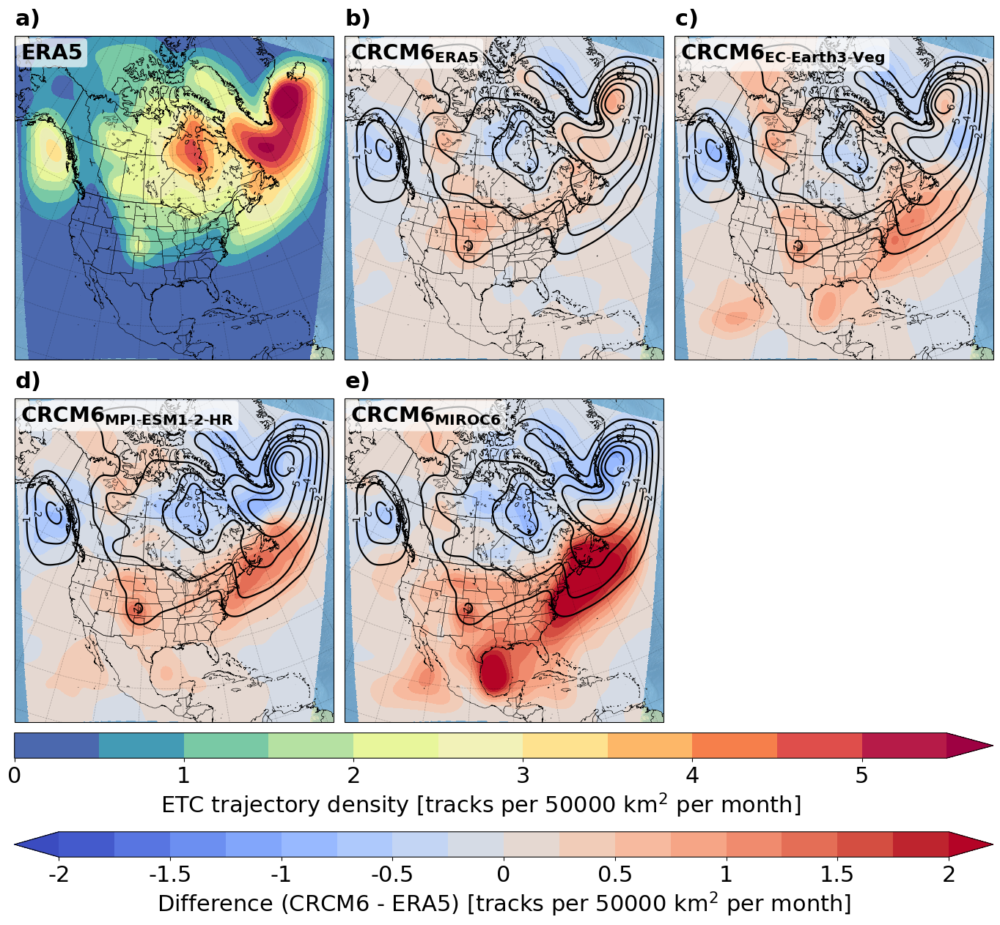

In [5]:
density = {}

for sim in simulations:
    if sim == 'ERA5':
        density[sim] = ds_dens['ERA5'].sel(season='ALL').density_ETCs * 50000.
    else:
        density[sim] = ds_dens[sim].sel(season='ALL').density_ETCs * 50000. - ds_dens['ERA5'].sel(season='ALL').density_ETCs * 50000.
        
plot_map(
    density,
    cont = density['ERA5'],
    contour_levels=list(np.arange(0, 11, 1)),
    vmin_ERA5=0,
    vmax_ERA5=5.5,
    step_ERA5=0.5,
    vmin_sim=-2,
    vmax_sim=2,
    step_sim=0.25,
    label_ERA5 = 'ETC trajectory density [tracks per $50 000~\mathrm{km^2}$ per month]',
    label_sim  = 'Difference (CRCM6 - ERA5) [tracks per $50 000~\mathrm{km^2}$ per month]',
    style='contourf'
)

plt.savefig(f"/home/vdemeyer/projects/rrg-gachon/vdemeyer/ALL/PLOT/ETC_density_hist{tc_tag}.png", dpi=300, bbox_inches="tight")

## EETCs Cumulative Metric and difference between simulations and ERA5

Les simulations ont été regrillées sur la grille d'ERA5 pour la comparaison sur une grille commune. Pour obtenir le surplus par rapport au centile, on utilise total_ext_EETCs_total qui représente le volume totale de PR ou WS dans les 1000km d'un cyclone lorsque la variable est extrême, et on y retire la valeur du centile car ce n'est pas fait en amont (pour cela, on utilise le nombre de fois qu'on a excédé le centile count_ext_EETCs_total que l'on multiplie par la valeur du centile per_regridded[sim, 'pr'].sel(quantile=0.99).pr).

### Precipitation

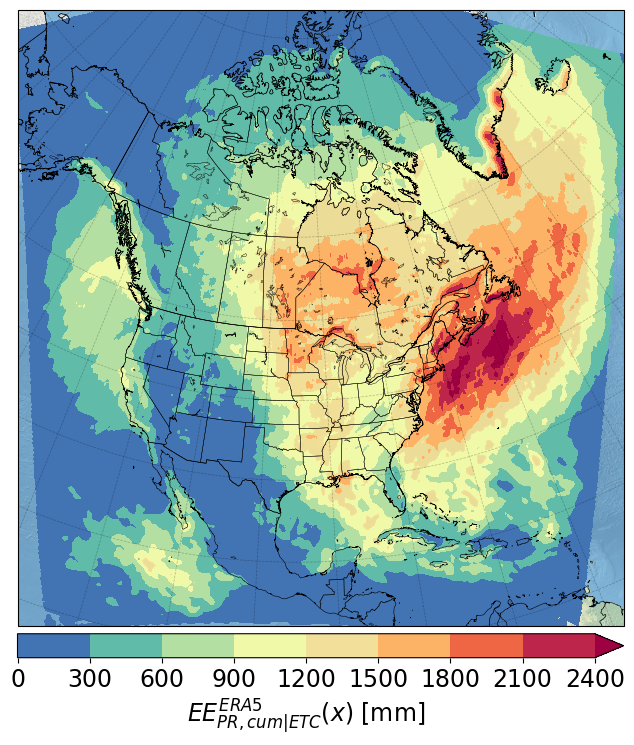

In [5]:
total_era5 = data['total_ext_EETCs_total']['ERA5'].sel(quantile=0.99, variable='pr')
percentile_era5 = per_regridded['ERA5', 'pr'].sel(quantile=0.99).pr
count_era5 = data['count_ext_EETCs_total']['ERA5'].sel(quantile=0.99, variable='pr')
EEcum_era5 = total_era5 - percentile_era5 * count_era5

plot_map_monoplot(
    EEcum_era5,
    vmin=0,
    vmax=2400,
    step=300,
    label=r'$EE_{PR,cum|ETC}^{ERA5}(x)$ [mm]',
)

plt.savefig(f"/home/vdemeyer/projects/rrg-gachon/vdemeyer/ALL/PLOT/PR_hist_ERA5{tc_tag}.png", dpi=300, bbox_inches="tight")

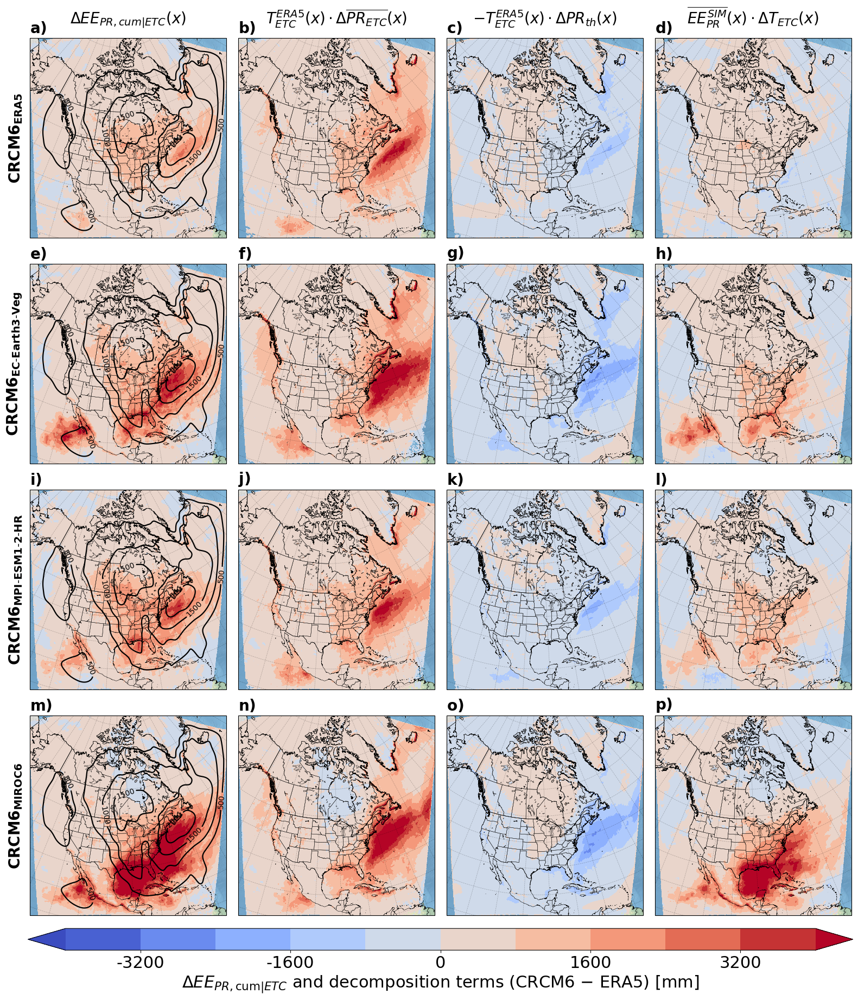

In [7]:
term_total = {}
term1 = {}
term2 = {}
term3 = {}
cont_total = {}
cont_terms = {}
contour_levels_term_total = {}
contour_levels_terms = {}

steps_term_total = {
    "UBB": 500,
    "UBD": 500,
    "UBE": 500,
    "UBF": 500,
}

steps_terms = {
    "UBB": 350,
    "UBD": 600,
    "UBE": 500,
    "UBF": 900,
}

for sim in simulations:
    if sim == 'ERA5':
        total_era5 = data['total_ext_EETCs_total']['ERA5'].sel(quantile=0.99, variable='pr')
        percentile_era5 = per_regridded['ERA5', 'pr'].sel(quantile=0.99).pr
        count_era5 = data['count_ext_EETCs_total']['ERA5'].sel(quantile=0.99, variable='pr')
        EEcum_era5 = total_era5 - percentile_era5 * count_era5
    else:
        total_sim = data['total_ext_EETCs_total'][sim].sel(quantile=0.99, variable='pr')
        percentile_sim = per_regridded[sim, 'pr'].sel(quantile=0.99).pr
        count_sim = data['count_ext_EETCs_total'][sim].sel(quantile=0.99, variable='pr')
        EEcum_sim = total_sim - (percentile_sim * count_sim)

        diff = EEcum_sim.fillna(0) - EEcum_era5.fillna(0)
        term_total[sim] = diff.where((np.abs(EEcum_sim) > 0.) | (np.abs(EEcum_era5) > 0.))

        mean_sim = total_sim / count_sim
        mean_era5 = total_era5 / count_era5
        term1[sim] = count_era5.fillna(0) * (mean_sim.fillna(0) - mean_era5.fillna(0))
        term2[sim] = count_era5.fillna(0) * (percentile_era5.fillna(0) - percentile_sim.fillna(0))

        mean_sim_exc = (total_sim - percentile_sim * count_sim) / count_sim.where(count_sim > 0)
        term3[sim] = mean_sim_exc.fillna(0) * (count_sim.fillna(0) - count_era5.fillna(0))

        active_points = (count_sim > 0) | (count_era5 > 0)
        term1[sim] = term1[sim].where(active_points)
        term2[sim] = term2[sim].where(active_points)
        term3[sim] = term3[sim].where(active_points)

        cont_total[sim] = EEcum_era5.where(EEcum_era5 > 0.)
        cont_terms[sim] = term_total[sim]

        contour_levels_term_total[sim] = np.arange(
            -np.ceil(12000/steps_term_total[sim])*steps_term_total[sim],
            np.ceil(12000/steps_term_total[sim])*steps_term_total[sim] + steps_term_total[sim],
            steps_term_total[sim]
        )
        contour_levels_terms[sim] = np.arange(
            -np.ceil(10000/steps_terms[sim])*steps_terms[sim],
            np.ceil(10000/steps_terms[sim])*steps_terms[sim] + steps_terms[sim],
            steps_terms[sim]
        )

plot_map_four_per_four(
    [term_total, term1, term2, term3],
    sims=[s for s in simulations if s != 'ERA5'],
    cont=[cont_total],
    contour_levels=[contour_levels_term_total],
    sigma=7,
    colormap='coolwarm',
    vmin=-4000,
    vmax=4000,
    step=800,
    label=r"$\Delta EE_{PR,\mathrm{cum}|ETC}$ and decomposition terms (CRCM6 $-$ ERA5) [mm]",
    style='contourf'
)

plt.savefig(f"/home/vdemeyer/projects/rrg-gachon/vdemeyer/ALL/PLOT/PR_hist_vs_ERA5{tc_tag}.png", dpi=300, bbox_inches="tight")

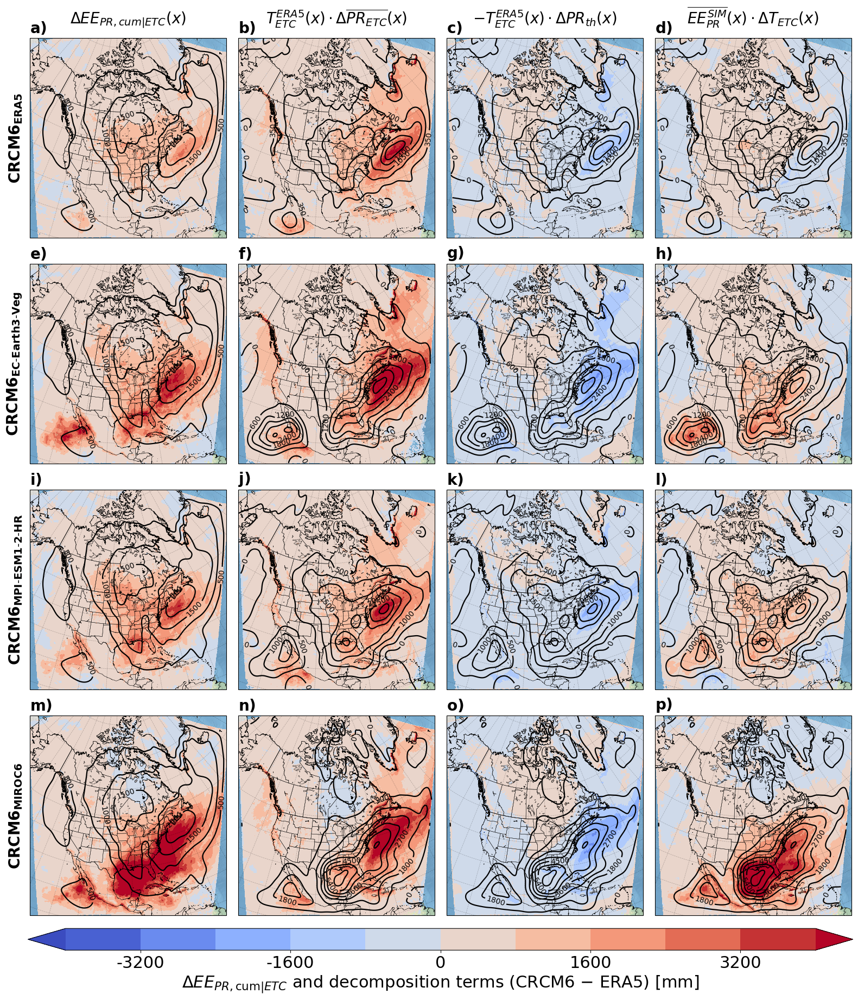

In [5]:
term_total = {}
term1 = {}
term2 = {}
term3 = {}
cont_total = {}
cont_terms = {}
contour_levels_term_total = {}
contour_levels_terms = {}

steps_term_total = {
    "UBB": 500,
    "UBD": 500,
    "UBE": 500,
    "UBF": 500,
}

steps_terms = {
    "UBB": 350,
    "UBD": 600,
    "UBE": 500,
    "UBF": 900,
}

for sim in simulations:
    if sim == 'ERA5':
        total_era5 = data['total_ext_EETCs_total']['ERA5'].sel(quantile=0.99, variable='pr')
        percentile_era5 = per_regridded['ERA5', 'pr'].sel(quantile=0.99).pr
        count_era5 = data['count_ext_EETCs_total']['ERA5'].sel(quantile=0.99, variable='pr')
        EEcum_era5 = total_era5 - percentile_era5 * count_era5
    else:
        total_sim = data['total_ext_EETCs_total'][sim].sel(quantile=0.99, variable='pr')
        percentile_sim = per_regridded[sim, 'pr'].sel(quantile=0.99).pr
        count_sim = data['count_ext_EETCs_total'][sim].sel(quantile=0.99, variable='pr')
        EEcum_sim = total_sim - (percentile_sim * count_sim)

        diff = EEcum_sim.fillna(0) - EEcum_era5.fillna(0)
        term_total[sim] = diff.where((np.abs(EEcum_sim) > 0.) | (np.abs(EEcum_era5) > 0.))

        mean_sim = total_sim / count_sim
        mean_era5 = total_era5 / count_era5
        term1[sim] = count_era5.fillna(0) * (mean_sim.fillna(0) - mean_era5.fillna(0))
        term2[sim] = count_era5.fillna(0) * (percentile_era5.fillna(0) - percentile_sim.fillna(0))

        mean_sim_exc = (total_sim - percentile_sim * count_sim) / count_sim.where(count_sim > 0)
        term3[sim] = mean_sim_exc.fillna(0) * (count_sim.fillna(0) - count_era5.fillna(0))

        active_points = (count_sim > 0) | (count_era5 > 0)
        term1[sim] = term1[sim].where(active_points)
        term2[sim] = term2[sim].where(active_points)
        term3[sim] = term3[sim].where(active_points)

        cont_total[sim] = EEcum_era5.where(EEcum_era5 > 0.)
        cont_terms[sim] = term_total[sim]

        contour_levels_term_total[sim] = np.arange(
            -np.ceil(12000/steps_term_total[sim])*steps_term_total[sim],
            np.ceil(12000/steps_term_total[sim])*steps_term_total[sim] + steps_term_total[sim],
            steps_term_total[sim]
        )
        contour_levels_terms[sim] = np.arange(
            -np.ceil(10000/steps_terms[sim])*steps_terms[sim],
            np.ceil(10000/steps_terms[sim])*steps_terms[sim] + steps_terms[sim],
            steps_terms[sim]
        )

plot_map_four_per_four(
    [term_total, term1, term2, term3],
    sims=[s for s in simulations if s != 'ERA5'],
    cont=[cont_total, cont_terms],
    contour_levels=[contour_levels_term_total, contour_levels_terms],
    sigma=7,
    colormap='coolwarm',
    vmin=-4000,
    vmax=4000,
    step=800,
    label=r"$\Delta EE_{PR,\mathrm{cum}|ETC}$ and decomposition terms (CRCM6 $-$ ERA5) [mm]",
    style='contourf'
)

# plt.savefig(f"/home/vdemeyer/projects/rrg-gachon/vdemeyer/ALL/PLOT/PR_hist_vs_ERA5{tc_tag}.png", dpi=300, bbox_inches="tight")

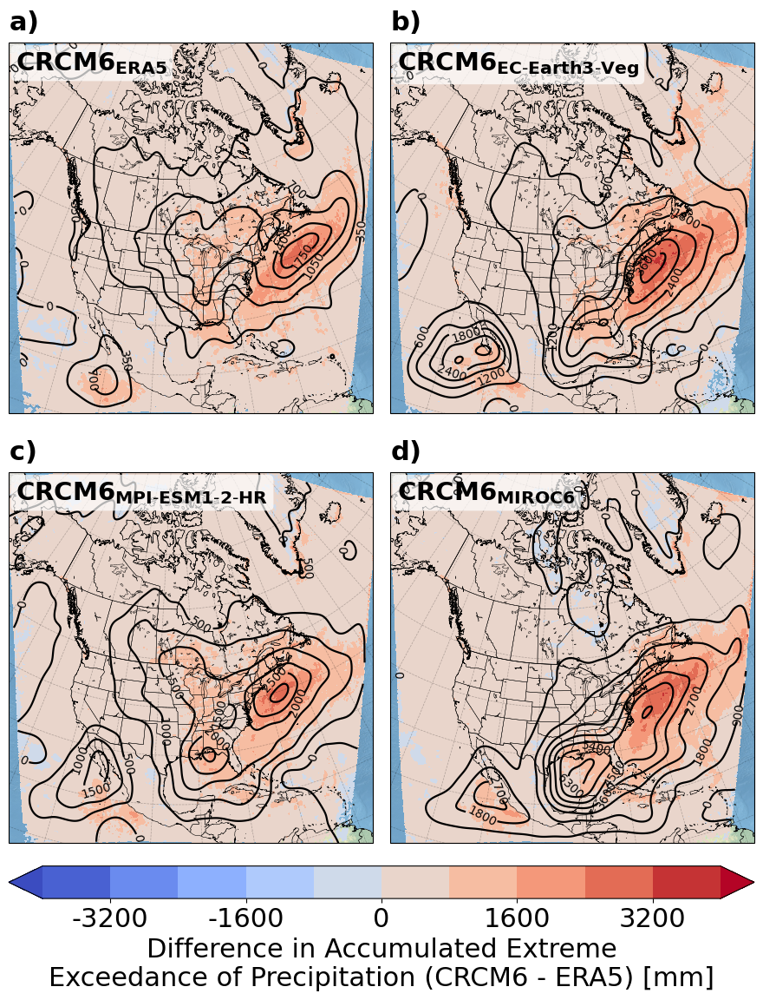

In [8]:
term1 = {}
term2 = {}
combined_term = {}
cont = {}
contour_levels = {}

steps = {
    "UBB": 350,
    "UBD": 600,
    "UBE": 500,
    "UBF": 900,
}

for sim in simulations:
    if sim == 'ERA5':
        total_era5 = data['total_ext_EETCs_total']['ERA5'].sel(quantile=0.99, variable='pr')
        percentile_era5 = per_regridded['ERA5', 'pr'].sel(quantile=0.99).pr
        count_era5 = data['count_ext_EETCs_total']['ERA5'].sel(quantile=0.99, variable='pr')
        EEcum_era5 = total_era5 - percentile_era5 * count_era5
    else:
        total_sim = data['total_ext_EETCs_total'][sim].sel(quantile=0.99, variable='pr')
        percentile_sim = per_regridded[sim, 'pr'].sel(quantile=0.99).pr
        count_sim = data['count_ext_EETCs_total'][sim].sel(quantile=0.99, variable='pr')
        EEcum_sim = total_sim - (percentile_sim * count_sim)
        
        diff = EEcum_sim.fillna(0) - EEcum_era5.fillna(0) # fillna(0) sert à remplacer les moyennes par 0 si pas de cyclones (NaN) de sorte à ce que 3 - NaN ne fasse pas NaN
        cont[sim] = diff.where((np.abs(EEcum_sim) > 0.) | (np.abs(EEcum_era5) > 0.))
        
        mean_sim = total_sim / count_sim
        mean_era5 = total_era5 / count_era5
        term1[sim] = count_era5.fillna(0) * (mean_sim.fillna(0) - mean_era5.fillna(0))
        
        term2[sim] = count_era5.fillna(0) * (percentile_era5.fillna(0) - percentile_sim.fillna(0))

        active_points = (count_sim > 0) | (count_era5 > 0) # Crée un masque qui est True si ERA5 OU UB_ a eu au moins un cyclone. Si aucun cyclone alors NaN.
        term1[sim] = term1[sim].where(active_points)
        term2[sim] = term2[sim].where(active_points)
        combined_term[sim] = term1[sim] + term2[sim]
        
        contour_levels[sim] = np.arange(-np.ceil(10000/steps[sim])*steps[sim], np.ceil(10000/steps[sim])*steps[sim] + steps[sim], steps[sim])

plot_map_terms_supp(
    combined_term,
    cont=cont,
    contour_levels=contour_levels,
    sigma=7,
    vmin=-4000,
    vmax=4000,
    step=800,
    label='Difference in Accumulated Extreme\nExceedance of Precipitation (CRCM6 - ERA5) [mm]',
    style='contourf'
)

plt.savefig(f"/home/vdemeyer/projects/rrg-gachon/vdemeyer/ALL/PLOT/supp_term1&2_PR_hist{tc_tag}.png", dpi=300, bbox_inches="tight")

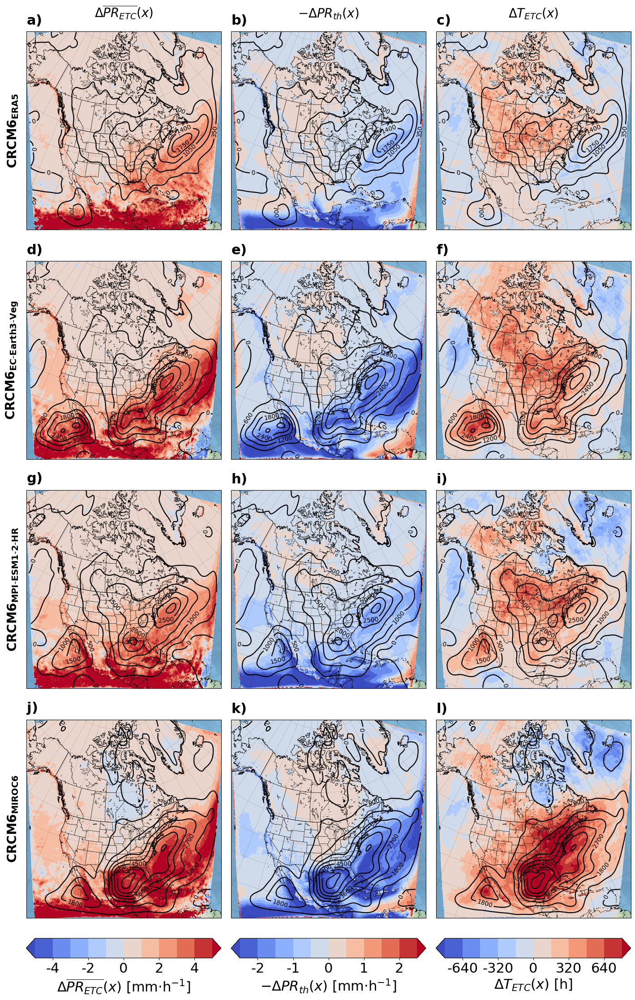

In [5]:
term1 = {}
term2 = {}
term3 = {}
cont = {}
contour_levels = {}

steps = {
    "UBB": 350,
    "UBD": 600,
    "UBE": 500,
    "UBF": 900,
}

for sim in simulations:
    if sim == 'ERA5':
        total_era5 = data['total_ext_EETCs_total']['ERA5'].sel(quantile=0.99, variable='pr')
        percentile_era5 = per_regridded['ERA5', 'pr'].sel(quantile=0.99).pr
        count_era5 = data['count_ext_EETCs_total']['ERA5'].sel(quantile=0.99, variable='pr')
        EEcum_era5 = total_era5 - percentile_era5 * count_era5
    else:
        total_sim = data['total_ext_EETCs_total'][sim].sel(quantile=0.99, variable='pr')
        percentile_sim = per_regridded[sim, 'pr'].sel(quantile=0.99).pr
        count_sim = data['count_ext_EETCs_total'][sim].sel(quantile=0.99, variable='pr')
        EEcum_sim = total_sim - (percentile_sim * count_sim)
        
        diff = EEcum_sim.fillna(0) - EEcum_era5.fillna(0) # fillna(0) sert à remplacer les moyennes par 0 si pas de cyclones (NaN) de sorte à ce que 3 - NaN ne fasse pas NaN
        cont[sim] = diff.where((np.abs(EEcum_sim) > 0.) | (np.abs(EEcum_era5) > 0.))

        mean_sim = total_sim / count_sim
        mean_era5 = total_era5 / count_era5
        term1[sim] = mean_sim.fillna(0) - mean_era5.fillna(0)
        term2[sim] = percentile_era5.fillna(0) - percentile_sim.fillna(0)
        term3[sim] = count_sim.fillna(0) - count_era5.fillna(0)

        active_points = (count_sim > 0) | (count_era5 > 0) # Crée un masque qui est True si ERA5 OU UB_ a eu au moins un cyclone. Si aucun cyclone alors NaN.
        term1[sim] = term1[sim].where(active_points)
        term2[sim] = term2[sim].where(active_points)
        term3[sim] = term3[sim].where(active_points)

        contour_levels[sim] = np.arange(-np.ceil(10000/steps[sim])*steps[sim], np.ceil(10000/steps[sim])*steps[sim] + steps[sim], steps[sim])
        
plot_map_terms_3cbar(
    [term1, term2, term3],
    col_cfg=[
        {"vmin": -5., "vmax": 5., "step": 1., "label": r'$\Delta \overline{PR_{ETC}}(x)$ [mm·h$^{-1}$]', "colormap": "coolwarm", "extend_opt": "both"},
        {"vmin": -2.5, "vmax": 2.5, "step": 0.5, "label": r'$- \Delta PR_{th}(x)$ [mm·h$^{-1}$]', "colormap": "coolwarm", "extend_opt": "both"},
        {"vmin": -800, "vmax": 800, "step": 160, "label": r'$\Delta T_{ETC}(x)$ [h]', "colormap": "coolwarm", "extend_opt": "both"}
    ],
    cont=cont,
    contour_levels=contour_levels,
    sigma=7,
    style="contourf",
)

plt.savefig(f"/home/vdemeyer/projects/rrg-gachon/vdemeyer/ALL/PLOT/supp_terms_PR_hist{tc_tag}.png", dpi=300, bbox_inches="tight")

### Surface Wind

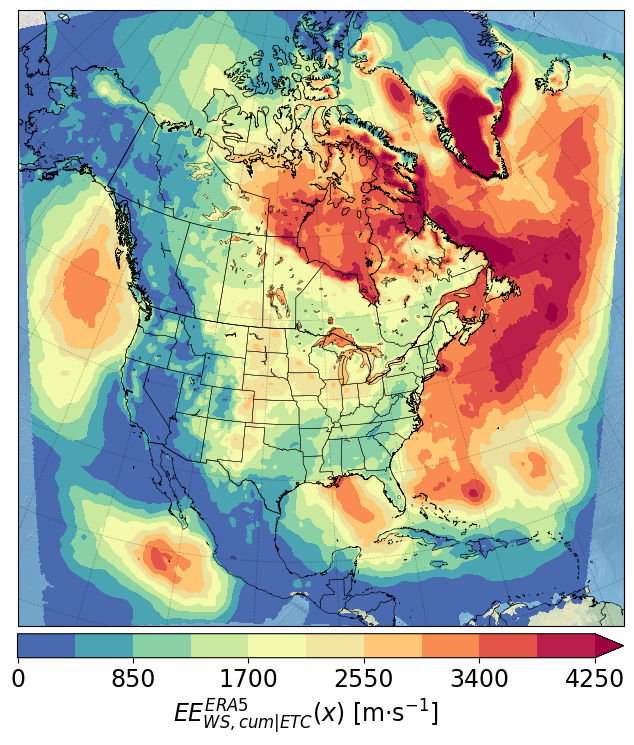

In [6]:
total_era5 = data['total_ext_EETCs_total']['ERA5'].sel(quantile=0.99, variable='ws')
percentile_era5 = per_regridded['ERA5', 'ws'].sel(quantile=0.99).surf_wind
count_era5 = data['count_ext_EETCs_total']['ERA5'].sel(quantile=0.99, variable='ws')
EEcum_era5 = total_era5 - percentile_era5 * count_era5

plot_map_monoplot(
    EEcum_era5,
    vmin=0,
    vmax=4250,
    step=425,
    label=r'$EE_{WS,cum|ETC}^{ERA5}(x)$ [m$\cdot$s$^{-1}$]',
)

plt.savefig(f"/home/vdemeyer/projects/rrg-gachon/vdemeyer/ALL/PLOT/WS_hist_ERA5{tc_tag}.png", dpi=300, bbox_inches="tight")

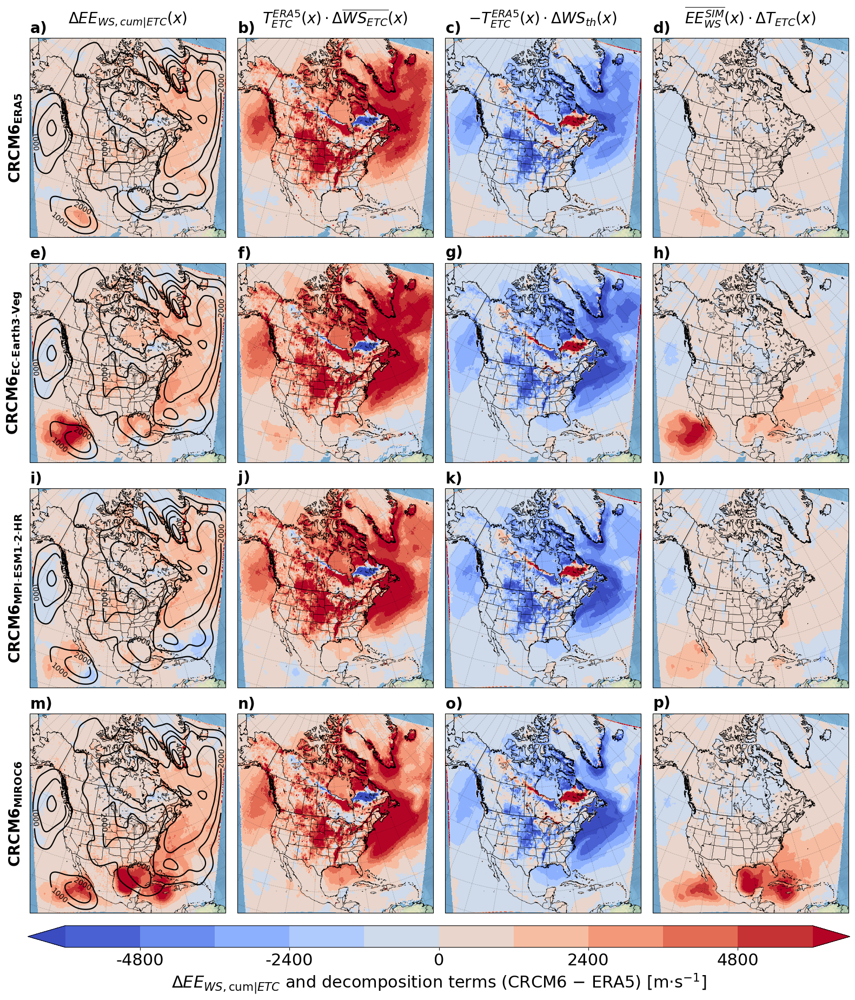

In [6]:
term_total = {}
term1 = {}
term2 = {}
term3 = {}
cont_total = {}
cont_terms = {}
contour_levels_term_total = {}
contour_levels_terms = {}

steps_term_total = {
    "UBB": 1000,
    "UBD": 1000,
    "UBE": 1000,
    "UBF": 1000,
}

steps_terms = {
    "UBB": 500,
    "UBD": 800,
    "UBE": 500,
    "UBF": 1000,
}

for sim in simulations:
    if sim == 'ERA5':
        total_era5 = data['total_ext_EETCs_total']['ERA5'].sel(quantile=0.99, variable='ws')
        percentile_era5 = per_regridded['ERA5', 'ws'].sel(quantile=0.99).surf_wind
        count_era5 = data['count_ext_EETCs_total']['ERA5'].sel(quantile=0.99, variable='ws')
        EEcum_era5 = total_era5 - percentile_era5 * count_era5
    else:
        total_sim = data['total_ext_EETCs_total'][sim].sel(quantile=0.99, variable='ws')
        percentile_sim = per_regridded[sim, 'ws'].sel(quantile=0.99).surf_wind
        count_sim = data['count_ext_EETCs_total'][sim].sel(quantile=0.99, variable='ws')
        EEcum_sim = total_sim - (percentile_sim * count_sim)

        diff = EEcum_sim.fillna(0) - EEcum_era5.fillna(0)
        term_total[sim] = diff.where((np.abs(EEcum_sim) > 0.) | (np.abs(EEcum_era5) > 0.))

        mean_sim = total_sim / count_sim
        mean_era5 = total_era5 / count_era5
        term1[sim] = count_era5.fillna(0) * (mean_sim.fillna(0) - mean_era5.fillna(0))
        term2[sim] = count_era5.fillna(0) * (percentile_era5.fillna(0) - percentile_sim.fillna(0))

        mean_sim_exc = (total_sim - percentile_sim * count_sim) / count_sim.where(count_sim > 0)
        term3[sim] = mean_sim_exc.fillna(0) * (count_sim.fillna(0) - count_era5.fillna(0))

        active_points = (count_sim > 0) | (count_era5 > 0)
        term1[sim] = term1[sim].where(active_points)
        term2[sim] = term2[sim].where(active_points)
        term3[sim] = term3[sim].where(active_points)

        cont_total[sim] = EEcum_era5.where(EEcum_era5 > 0.)
        cont_terms[sim] = term_total[sim]

        contour_levels_term_total[sim] = np.arange(
            -np.ceil(12000/steps_term_total[sim])*steps_term_total[sim],
            np.ceil(12000/steps_term_total[sim])*steps_term_total[sim] + steps_term_total[sim],
            steps_term_total[sim]
        )
        contour_levels_terms[sim] = np.arange(
            -np.ceil(10000/steps_terms[sim])*steps_terms[sim],
            np.ceil(10000/steps_terms[sim])*steps_terms[sim] + steps_terms[sim],
            steps_terms[sim]
        )

plot_map_four_per_four(
    [term_total, term1, term2, term3],
    sims=[s for s in simulations if s != 'ERA5'],
    cont=[cont_total],
    contour_levels=[contour_levels_term_total],
    sigma=7,
    colormap='coolwarm',
    vmin=-6000,
    vmax=6000,
    step=1200,
    label=r"$\Delta EE_{WS,\mathrm{cum}|ETC}$ and decomposition terms (CRCM6 $-$ ERA5) [m$\cdot$s$^{-1}$]",
    style='contourf'
)

plt.savefig(f"/home/vdemeyer/projects/rrg-gachon/vdemeyer/ALL/PLOT/WS_hist_vs_ERA5{tc_tag}.png", dpi=300, bbox_inches="tight")

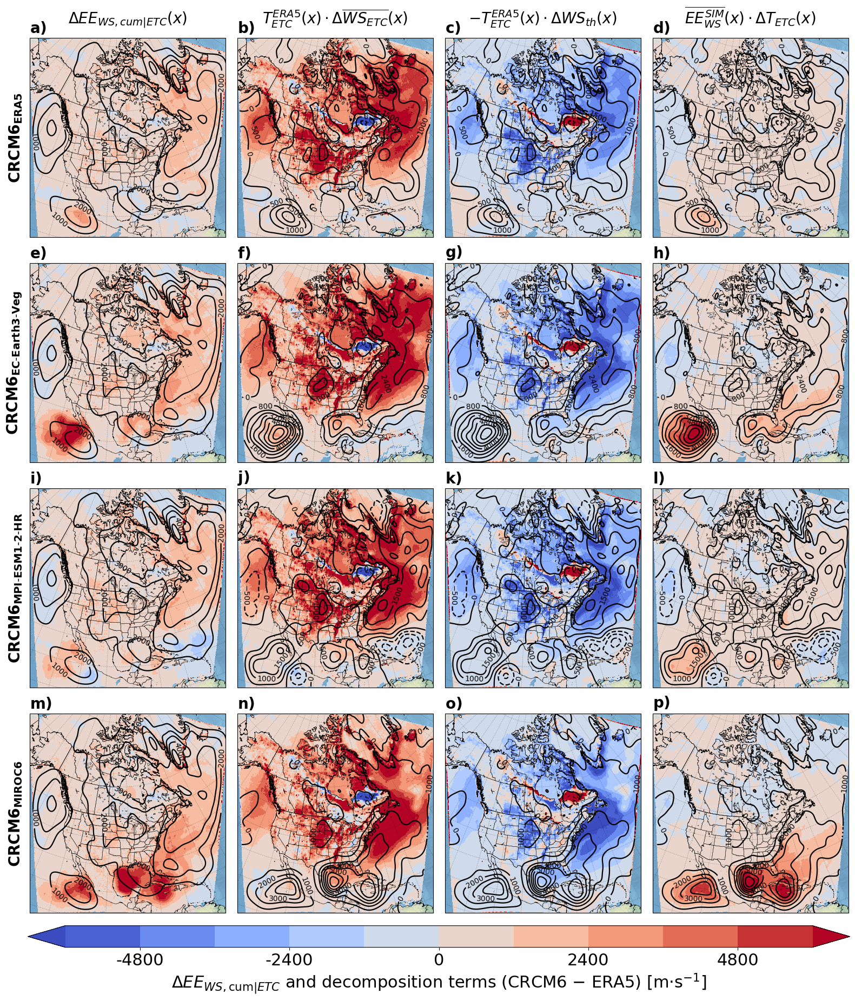

In [6]:
term_total = {}
term1 = {}
term2 = {}
term3 = {}
cont_total = {}
cont_terms = {}
contour_levels_term_total = {}
contour_levels_terms = {}

steps_term_total = {
    "UBB": 1000,
    "UBD": 1000,
    "UBE": 1000,
    "UBF": 1000,
}

steps_terms = {
    "UBB": 500,
    "UBD": 800,
    "UBE": 500,
    "UBF": 1000,
}

for sim in simulations:
    if sim == 'ERA5':
        total_era5 = data['total_ext_EETCs_total']['ERA5'].sel(quantile=0.99, variable='ws')
        percentile_era5 = per_regridded['ERA5', 'ws'].sel(quantile=0.99).surf_wind
        count_era5 = data['count_ext_EETCs_total']['ERA5'].sel(quantile=0.99, variable='ws')
        EEcum_era5 = total_era5 - percentile_era5 * count_era5
    else:
        total_sim = data['total_ext_EETCs_total'][sim].sel(quantile=0.99, variable='ws')
        percentile_sim = per_regridded[sim, 'ws'].sel(quantile=0.99).surf_wind
        count_sim = data['count_ext_EETCs_total'][sim].sel(quantile=0.99, variable='ws')
        EEcum_sim = total_sim - (percentile_sim * count_sim)

        diff = EEcum_sim.fillna(0) - EEcum_era5.fillna(0)
        term_total[sim] = diff.where((np.abs(EEcum_sim) > 0.) | (np.abs(EEcum_era5) > 0.))

        mean_sim = total_sim / count_sim
        mean_era5 = total_era5 / count_era5
        term1[sim] = count_era5.fillna(0) * (mean_sim.fillna(0) - mean_era5.fillna(0))
        term2[sim] = count_era5.fillna(0) * (percentile_era5.fillna(0) - percentile_sim.fillna(0))

        mean_sim_exc = (total_sim - percentile_sim * count_sim) / count_sim.where(count_sim > 0)
        term3[sim] = mean_sim_exc.fillna(0) * (count_sim.fillna(0) - count_era5.fillna(0))

        active_points = (count_sim > 0) | (count_era5 > 0)
        term1[sim] = term1[sim].where(active_points)
        term2[sim] = term2[sim].where(active_points)
        term3[sim] = term3[sim].where(active_points)

        cont_total[sim] = EEcum_era5.where(EEcum_era5 > 0.)
        cont_terms[sim] = term_total[sim]

        contour_levels_term_total[sim] = np.arange(
            -np.ceil(12000/steps_term_total[sim])*steps_term_total[sim],
            np.ceil(12000/steps_term_total[sim])*steps_term_total[sim] + steps_term_total[sim],
            steps_term_total[sim]
        )
        contour_levels_terms[sim] = np.arange(
            -np.ceil(10000/steps_terms[sim])*steps_terms[sim],
            np.ceil(10000/steps_terms[sim])*steps_terms[sim] + steps_terms[sim],
            steps_terms[sim]
        )

plot_map_four_per_four(
    [term_total, term1, term2, term3],
    sims=[s for s in simulations if s != 'ERA5'],
    cont=[cont_total, cont_terms],
    contour_levels=[contour_levels_term_total, contour_levels_terms],
    sigma=7,
    colormap='coolwarm',
    vmin=-6000,
    vmax=6000,
    step=1200,
    label=r"$\Delta EE_{WS,\mathrm{cum}|ETC}$ and decomposition terms (CRCM6 $-$ ERA5) [m$\cdot$s$^{-1}$]",
    style='contourf'
)

# plt.savefig(f"/home/vdemeyer/projects/rrg-gachon/vdemeyer/ALL/PLOT/WS_hist_vs_ERA5{tc_tag}.png", dpi=300, bbox_inches="tight")

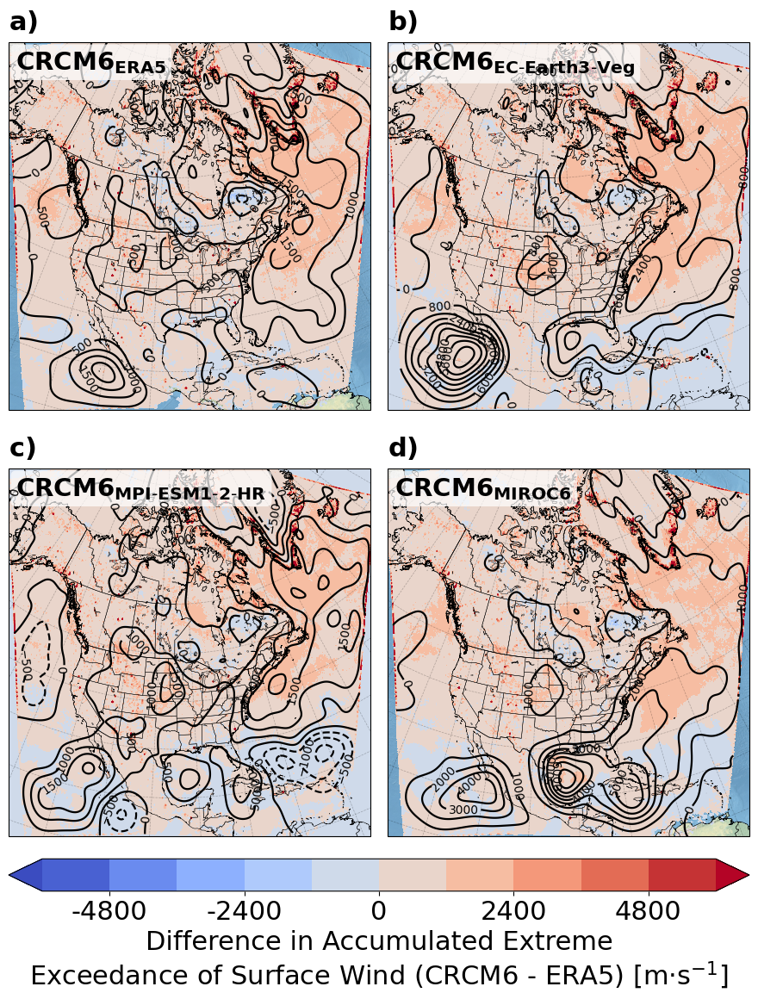

In [6]:
term1 = {}
term2 = {}
combined_term = {}
cont = {}
contour_levels = {}

steps = {
    "UBB": 500,
    "UBD": 800,
    "UBE": 500,
    "UBF": 1000,
}

for sim in simulations:
    if sim == 'ERA5':
        total_era5 = data['total_ext_EETCs_total']['ERA5'].sel(quantile=0.99, variable='ws')
        percentile_era5 = per_regridded['ERA5', 'ws'].sel(quantile=0.99).surf_wind
        count_era5 = data['count_ext_EETCs_total']['ERA5'].sel(quantile=0.99, variable='ws')
        EEcum_era5 = total_era5 - percentile_era5 * count_era5
    else:
        total_sim = data['total_ext_EETCs_total'][sim].sel(quantile=0.99, variable='ws')
        percentile_sim = per_regridded[sim, 'ws'].sel(quantile=0.99).surf_wind
        count_sim = data['count_ext_EETCs_total'][sim].sel(quantile=0.99, variable='ws')
        EEcum_sim = total_sim - (percentile_sim * count_sim)
        
        diff = EEcum_sim.fillna(0) - EEcum_era5.fillna(0) # fillna(0) sert à remplacer les moyennes par 0 si pas de cyclones (NaN) de sorte à ce que 3 - NaN ne fasse pas NaN
        cont[sim] = diff.where((np.abs(EEcum_sim) > 0.) | (np.abs(EEcum_era5) > 0.))
        
        mean_sim = total_sim / count_sim
        mean_era5 = total_era5 / count_era5
        term1[sim] = count_era5.fillna(0) * (mean_sim.fillna(0) - mean_era5.fillna(0))

        term2[sim] = count_era5.fillna(0) * (percentile_era5.fillna(0) - percentile_sim.fillna(0))

        active_points = (count_sim > 0) | (count_era5 > 0) # Crée un masque qui est True si ERA5 OU UB_ a eu au moins un cyclone. Si aucun cyclone alors NaN.
        term1[sim] = term1[sim].where(active_points)
        term2[sim] = term2[sim].where(active_points)
        combined_term[sim] = term1[sim] + term2[sim]
       
        contour_levels[sim] = np.arange(-np.ceil(10000/steps[sim])*steps[sim], np.ceil(10000/steps[sim])*steps[sim] + steps[sim], steps[sim])

plot_map_terms_supp(
    combined_term,
    cont=cont,
    contour_levels=contour_levels,
    sigma=7,
    vmin=-6000,
    vmax=6000,
    step=1200,
    label='Difference in Accumulated Extreme\nExceedance of Surface Wind (CRCM6 - ERA5) [m$\cdot$s$^{-1}$]',
    style='contourf'
)

plt.savefig(f"/home/vdemeyer/projects/rrg-gachon/vdemeyer/ALL/PLOT/supp_term1&2_WS_hist{tc_tag}.png", dpi=300, bbox_inches="tight")

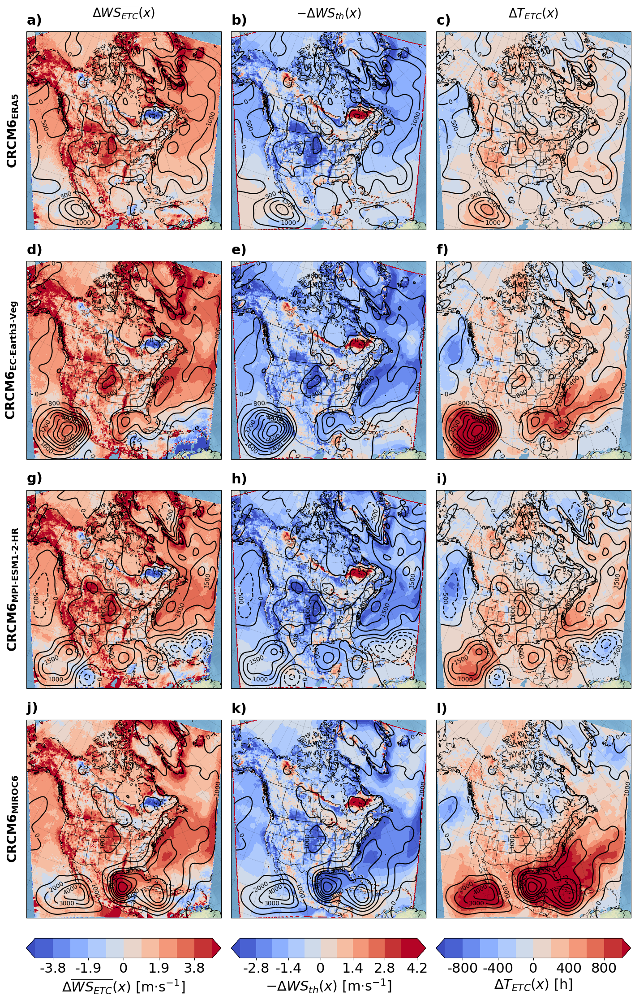

In [12]:
term1 = {}
term2 = {}
term3 = {}
cont = {}
contour_levels = {}
active_points_dict = {}

steps = {
    "UBB": 500,
    "UBD": 800,
    "UBE": 500,
    "UBF": 1000,
}

for sim in simulations:
    if sim == 'ERA5':
        total_era5 = data['total_ext_EETCs_total']['ERA5'].sel(quantile=0.99, variable='ws')
        percentile_era5 = per_regridded['ERA5', 'ws'].sel(quantile=0.99).surf_wind
        count_era5 = data['count_ext_EETCs_total']['ERA5'].sel(quantile=0.99, variable='ws')
        EEcum_era5 = total_era5 - percentile_era5 * count_era5
    else:
        total_sim = data['total_ext_EETCs_total'][sim].sel(quantile=0.99, variable='ws')
        percentile_sim = per_regridded[sim, 'ws'].sel(quantile=0.99).surf_wind
        count_sim = data['count_ext_EETCs_total'][sim].sel(quantile=0.99, variable='ws')
        EEcum_sim = total_sim - (percentile_sim * count_sim)
        
        diff = EEcum_sim.fillna(0) - EEcum_era5.fillna(0) # fillna(0) sert à remplacer les moyennes par 0 si pas de cyclones (NaN) de sorte à ce que 3 - NaN ne fasse pas NaN
        cont[sim] = diff.where((np.abs(EEcum_sim) > 0.) | (np.abs(EEcum_era5) > 0.))

        mean_sim = total_sim / count_sim
        mean_era5 = total_era5 / count_era5
        term1[sim] = mean_sim.fillna(0) - mean_era5.fillna(0)
        term2[sim] = percentile_era5.fillna(0) - percentile_sim.fillna(0)
        term3[sim] = count_sim.fillna(0) - count_era5.fillna(0)

        active_points = (count_sim > 0) | (count_era5 > 0) # Crée un masque qui est True si ERA5 OU UB_ a eu au moins un cyclone. Si aucun cyclone alors NaN.
        term1[sim] = term1[sim].where(active_points)
        term2[sim] = term2[sim].where(active_points)
        term3[sim] = term3[sim].where(active_points)

        contour_levels[sim] = np.arange(-np.ceil(10000/steps[sim])*steps[sim], np.ceil(10000/steps[sim])*steps[sim] + steps[sim], steps[sim])
        
plot_map_terms_3cbar(
    [term1, term2, term3],
    col_cfg=[
        {"vmin": -4.75, "vmax": 4.75, "step": 0.95, "label": r'$\Delta \overline{WS_{ETC}}(x)$ [m·s$^{-1}$]', "colormap": "coolwarm", "extend_opt": "both"},
        {"vmin": -3.5, "vmax": 3.5, "step": 0.7, "label": r'$- \Delta WS_{th}(x)$ [m·s$^{-1}$]', "colormap": "coolwarm", "extend_opt": "both"},
        {"vmin": -1000, "vmax": 1000, "step": 200, "label": r'$\Delta T_{ETC}(x)$ [h]', "colormap": "coolwarm", "extend_opt": "both"}
    ],
    cont=cont,
    contour_levels=contour_levels,
    sigma=7,
    style="contourf",
)

plt.savefig(f"/home/vdemeyer/projects/rrg-gachon/vdemeyer/ALL/PLOT/supp_terms_WS_hist{tc_tag}.png", dpi=300, bbox_inches="tight")

## Seasonal maps

### Density

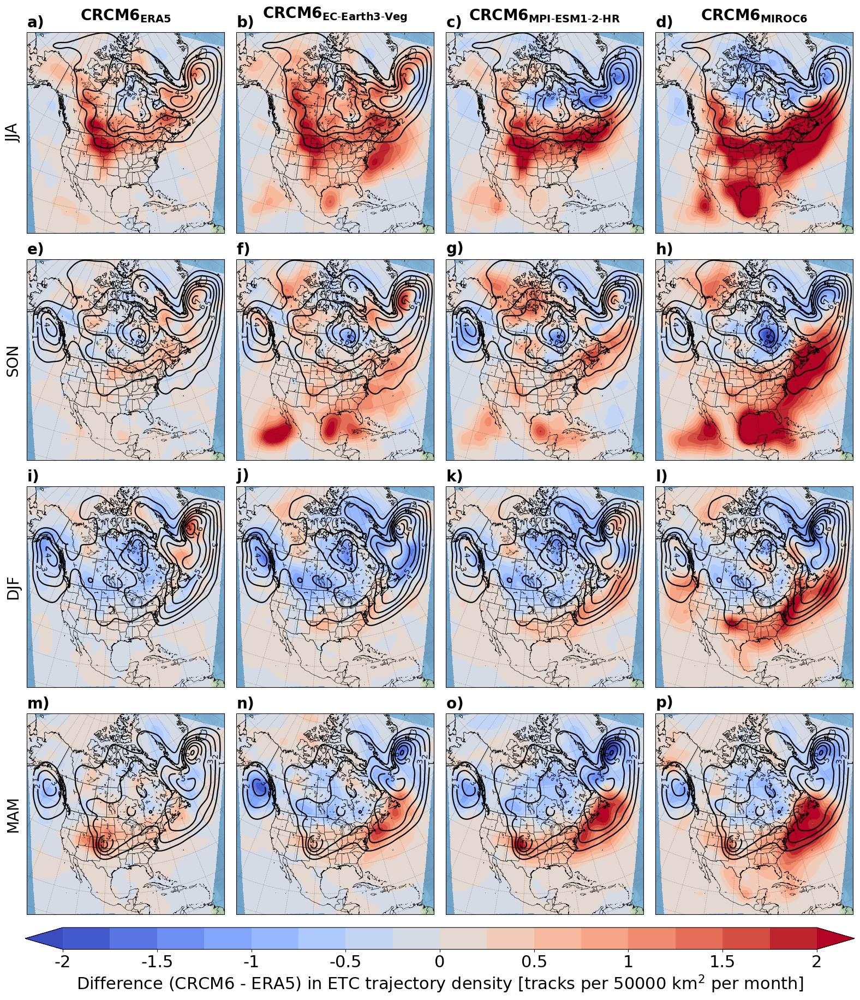

In [14]:
data_input = {}
cont = {}

for sim in simulations:
    for season in ['JJA', 'SON', 'DJF', 'MAM']:
        if sim == 'ERA5':
            continue
        data_input[sim, season] = (
            ds_dens[sim].sel(season=season).density_ETCs * 50000.
            - ds_dens['ERA5'].sel(season=season).density_ETCs * 50000.
        )
        
        cont[season] = ds_dens['ERA5'].sel(season=season).density_ETCs * 50000.

plot_map_four_per_four_season_density(
    data_input,
    cont=cont,
    contour_levels=list(np.arange(0, 15, 1)),
    sims=[s for s in simulations if s != 'ERA5'],
    colormap='coolwarm',
    vmin=-2,
    vmax=2,
    step=0.25,
    label='Difference (CRCM6 - ERA5) in ETC trajectory density [tracks per $50 000~\\mathrm{km^2}$ per month]',
    style='contourf'
)

plt.savefig(f"/home/vdemeyer/projects/rrg-gachon/vdemeyer/ALL/PLOT/supp_seasonal_ETC_density_hist{tc_tag}.png", dpi=300, bbox_inches="tight")

### Precipitation

#### UBB

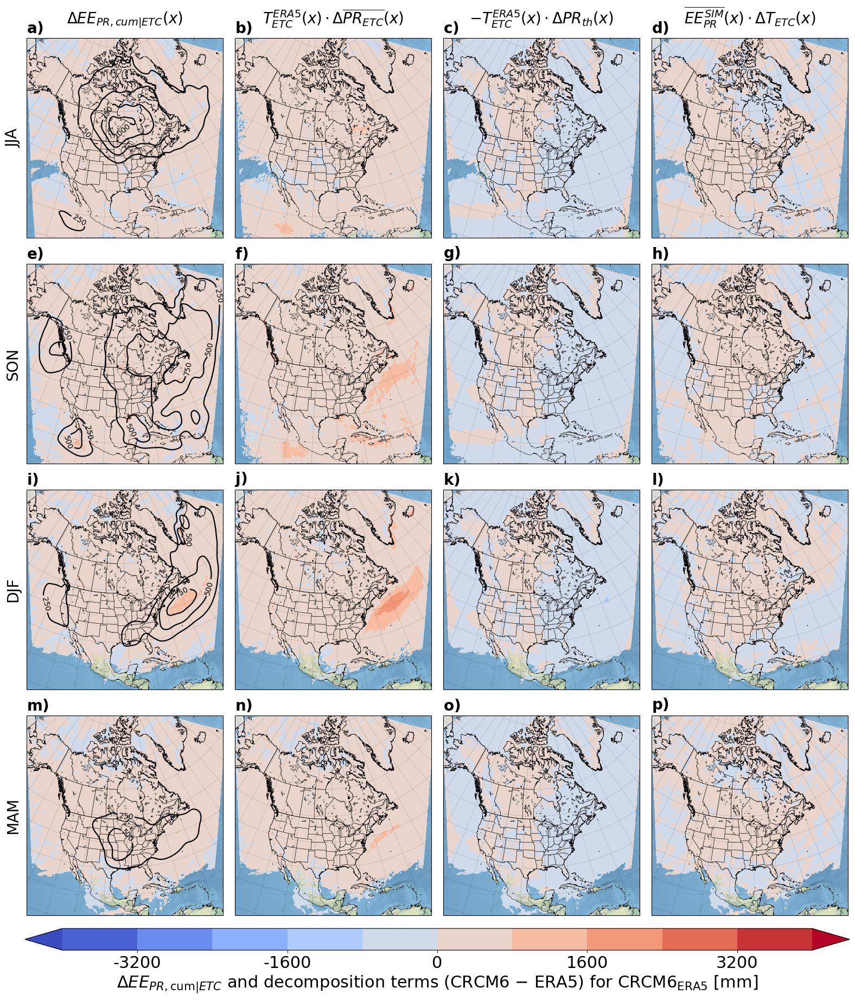

In [15]:
sim = [s for s in simulations if s != 'ERA5'][0]

term_total = {}
term1 = {}
term2 = {}
term3 = {}
cont_total = {}
cont_terms = {}
contour_levels_term_total = {}
contour_levels_terms = {}

steps_term_total = {'UBB': 250, 'UBD': 250, 'UBE': 250, 'UBF': 250}
steps_terms = {'UBB': 350, 'UBD': 600, 'UBE': 500, 'UBF': 900}

for season in ['JJA', 'SON', 'DJF', 'MAM']:
    total_era5 = data['total_ext_EETCs_seasonal']['ERA5'].sel(season=season, quantile=0.99, variable='pr')
    percentile_era5 = per_regridded['ERA5', 'pr'].sel(quantile=0.99).pr
    count_era5 = data['count_ext_EETCs_seasonal']['ERA5'].sel(season=season, quantile=0.99, variable='pr')
    EEcum_era5 = total_era5 - percentile_era5 * count_era5

    total_sim = data['total_ext_EETCs_seasonal'][sim].sel(season=season, quantile=0.99, variable='pr')
    percentile_sim = per_regridded[sim, 'pr'].sel(quantile=0.99).pr
    count_sim = data['count_ext_EETCs_seasonal'][sim].sel(season=season, quantile=0.99, variable='pr')
    EEcum_sim = total_sim - (percentile_sim * count_sim)

    diff = EEcum_sim.fillna(0) - EEcum_era5.fillna(0)
    term_total[season] = diff.where((np.abs(EEcum_sim) > 0.) | (np.abs(EEcum_era5) > 0.))

    mean_sim = total_sim / count_sim
    mean_era5 = total_era5 / count_era5
    term1[season] = count_era5.fillna(0) * (mean_sim.fillna(0) - mean_era5.fillna(0))
    term2[season] = count_era5.fillna(0) * (percentile_era5.fillna(0) - percentile_sim.fillna(0))

    mean_sim_exc = (total_sim - percentile_sim * count_sim) / count_sim.where(count_sim > 0)
    term3[season] = mean_sim_exc.fillna(0) * (count_sim.fillna(0) - count_era5.fillna(0))

    active_points = (count_sim > 0) | (count_era5 > 0)
    term1[season] = term1[season].where(active_points)
    term2[season] = term2[season].where(active_points)
    term3[season] = term3[season].where(active_points)

    cont_total[season] = EEcum_era5.where(EEcum_era5 > 0.)
    cont_terms[season] = term_total[season]

    contour_levels_term_total[season] = np.arange(
        -np.ceil(12000/steps_term_total[sim])*steps_term_total[sim],
        np.ceil(12000/steps_term_total[sim])*steps_term_total[sim] + steps_term_total[sim],
        steps_term_total[sim]
    )
    contour_levels_terms[season] = np.arange(
        -np.ceil(10000/steps_terms[sim])*steps_terms[sim],
        np.ceil(10000/steps_terms[sim])*steps_terms[sim] + steps_terms[sim],
        steps_terms[sim]
    )

plot_map_four_per_four_seasonal(
    [term_total, term1, term2, term3],
    cont=[cont_total],
    contour_levels=[contour_levels_term_total],
    sigma=7,
    colormap='coolwarm',
    vmin=-4000,
    vmax=4000,
    step=800,
    label=rf"$\Delta EE_{{PR,\mathrm{{cum}}|ETC}}$ and decomposition terms (CRCM6 $-$ ERA5) for {sim_label_nobold[sim]} [mm]",
    style='contourf'
)

plt.savefig(f"/home/vdemeyer/projects/rrg-gachon/vdemeyer/ALL/PLOT/supp_seasonal_CRCM6_ERA5_PR_hist_vs_ERA5{tc_tag}.png", dpi=300, bbox_inches="tight")

#### UBD

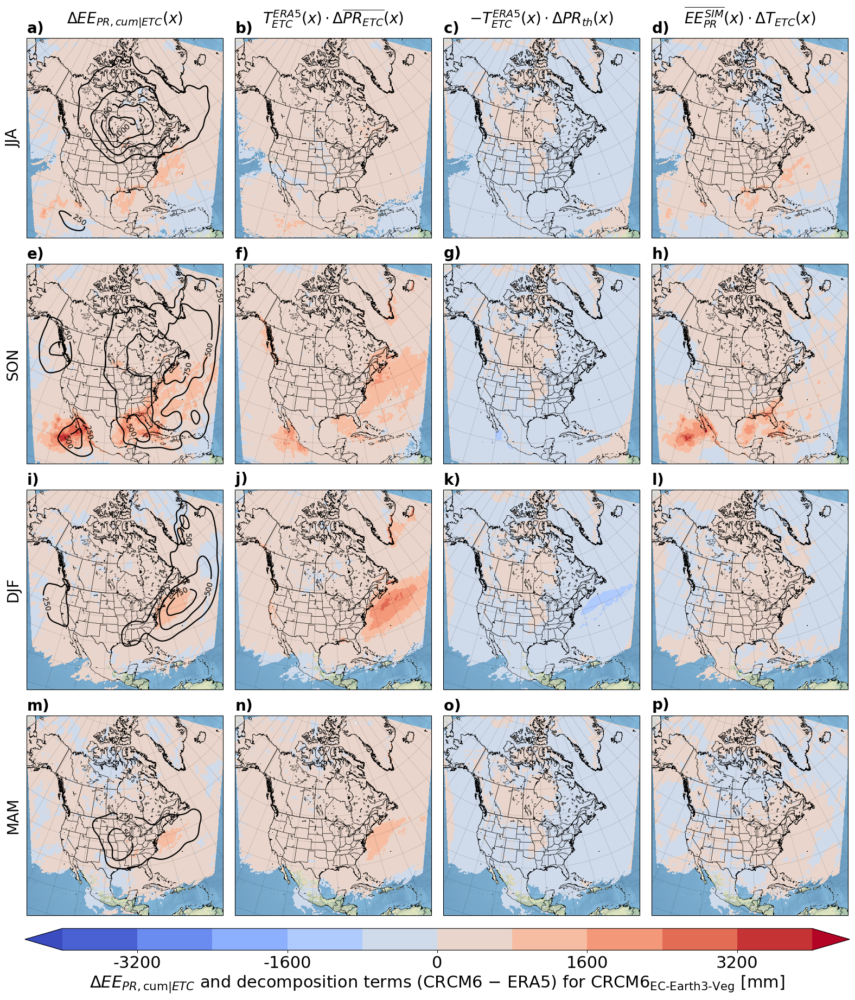

In [16]:
sim = [s for s in simulations if s != 'ERA5'][1]

term_total = {}
term1 = {}
term2 = {}
term3 = {}
cont_total = {}
cont_terms = {}
contour_levels_term_total = {}
contour_levels_terms = {}

steps_term_total = {'UBB': 250, 'UBD': 250, 'UBE': 250, 'UBF': 250}
steps_terms = {'UBB': 350, 'UBD': 600, 'UBE': 500, 'UBF': 900}

for season in ['JJA', 'SON', 'DJF', 'MAM']:
    total_era5 = data['total_ext_EETCs_seasonal']['ERA5'].sel(season=season, quantile=0.99, variable='pr')
    percentile_era5 = per_regridded['ERA5', 'pr'].sel(quantile=0.99).pr
    count_era5 = data['count_ext_EETCs_seasonal']['ERA5'].sel(season=season, quantile=0.99, variable='pr')
    EEcum_era5 = total_era5 - percentile_era5 * count_era5

    total_sim = data['total_ext_EETCs_seasonal'][sim].sel(season=season, quantile=0.99, variable='pr')
    percentile_sim = per_regridded[sim, 'pr'].sel(quantile=0.99).pr
    count_sim = data['count_ext_EETCs_seasonal'][sim].sel(season=season, quantile=0.99, variable='pr')
    EEcum_sim = total_sim - (percentile_sim * count_sim)

    diff = EEcum_sim.fillna(0) - EEcum_era5.fillna(0)
    term_total[season] = diff.where((np.abs(EEcum_sim) > 0.) | (np.abs(EEcum_era5) > 0.))

    mean_sim = total_sim / count_sim
    mean_era5 = total_era5 / count_era5
    term1[season] = count_era5.fillna(0) * (mean_sim.fillna(0) - mean_era5.fillna(0))
    term2[season] = count_era5.fillna(0) * (percentile_era5.fillna(0) - percentile_sim.fillna(0))

    mean_sim_exc = (total_sim - percentile_sim * count_sim) / count_sim.where(count_sim > 0)
    term3[season] = mean_sim_exc.fillna(0) * (count_sim.fillna(0) - count_era5.fillna(0))

    active_points = (count_sim > 0) | (count_era5 > 0)
    term1[season] = term1[season].where(active_points)
    term2[season] = term2[season].where(active_points)
    term3[season] = term3[season].where(active_points)

    cont_total[season] = EEcum_era5.where(EEcum_era5 > 0.)
    cont_terms[season] = term_total[season]

    contour_levels_term_total[season] = np.arange(
        -np.ceil(12000/steps_term_total[sim])*steps_term_total[sim],
        np.ceil(12000/steps_term_total[sim])*steps_term_total[sim] + steps_term_total[sim],
        steps_term_total[sim]
    )
    contour_levels_terms[season] = np.arange(
        -np.ceil(10000/steps_terms[sim])*steps_terms[sim],
        np.ceil(10000/steps_terms[sim])*steps_terms[sim] + steps_terms[sim],
        steps_terms[sim]
    )

plot_map_four_per_four_seasonal(
    [term_total, term1, term2, term3],
    cont=[cont_total],
    contour_levels=[contour_levels_term_total],
    sigma=7,
    colormap='coolwarm',
    vmin=-4000,
    vmax=4000,
    step=800,
    label=rf"$\Delta EE_{{PR,\mathrm{{cum}}|ETC}}$ and decomposition terms (CRCM6 $-$ ERA5) for {sim_label_nobold[sim]} [mm]",
    style='contourf'
)

plt.savefig(f"/home/vdemeyer/projects/rrg-gachon/vdemeyer/ALL/PLOT/supp_seasonal_CRCM6_EC-Earth3-Veg_PR_hist_vs_ERA5{tc_tag}.png", dpi=300, bbox_inches="tight")

#### UBE

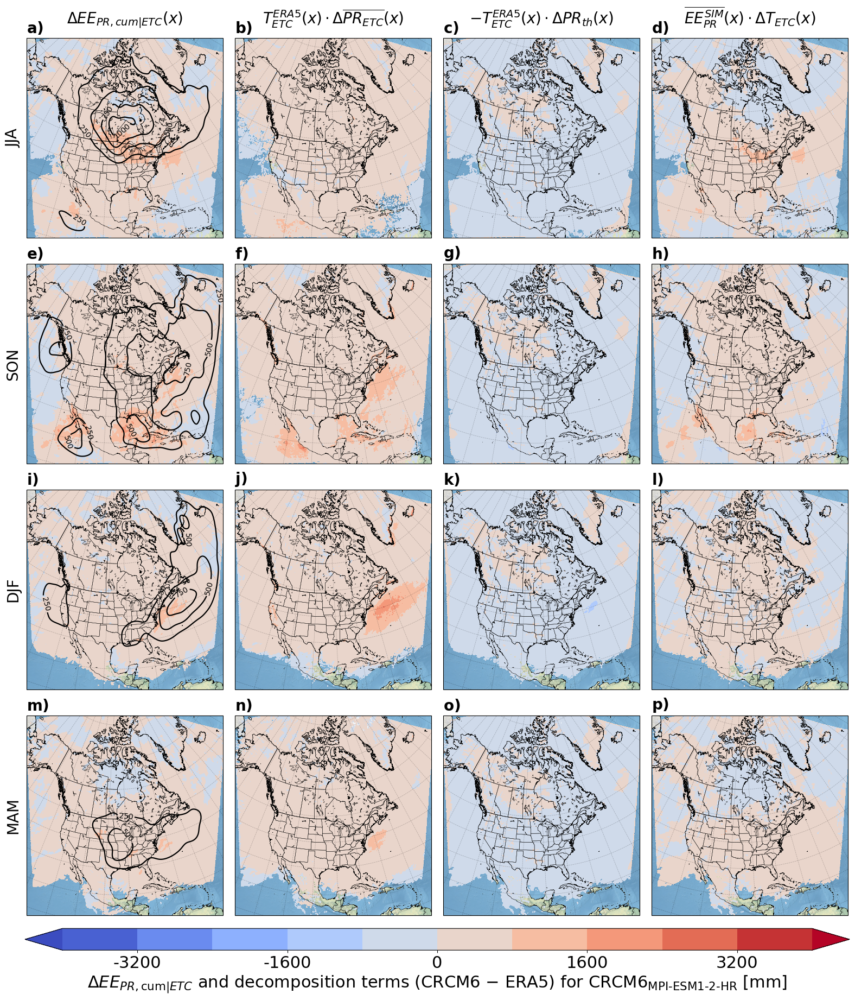

In [17]:
sim = [s for s in simulations if s != 'ERA5'][2]

term_total = {}
term1 = {}
term2 = {}
term3 = {}
cont_total = {}
cont_terms = {}
contour_levels_term_total = {}
contour_levels_terms = {}

steps_term_total = {'UBB': 250, 'UBD': 250, 'UBE': 250, 'UBF': 250}
steps_terms = {'UBB': 350, 'UBD': 600, 'UBE': 500, 'UBF': 900}

for season in ['JJA', 'SON', 'DJF', 'MAM']:
    total_era5 = data['total_ext_EETCs_seasonal']['ERA5'].sel(season=season, quantile=0.99, variable='pr')
    percentile_era5 = per_regridded['ERA5', 'pr'].sel(quantile=0.99).pr
    count_era5 = data['count_ext_EETCs_seasonal']['ERA5'].sel(season=season, quantile=0.99, variable='pr')
    EEcum_era5 = total_era5 - percentile_era5 * count_era5

    total_sim = data['total_ext_EETCs_seasonal'][sim].sel(season=season, quantile=0.99, variable='pr')
    percentile_sim = per_regridded[sim, 'pr'].sel(quantile=0.99).pr
    count_sim = data['count_ext_EETCs_seasonal'][sim].sel(season=season, quantile=0.99, variable='pr')
    EEcum_sim = total_sim - (percentile_sim * count_sim)

    diff = EEcum_sim.fillna(0) - EEcum_era5.fillna(0)
    term_total[season] = diff.where((np.abs(EEcum_sim) > 0.) | (np.abs(EEcum_era5) > 0.))

    mean_sim = total_sim / count_sim
    mean_era5 = total_era5 / count_era5
    term1[season] = count_era5.fillna(0) * (mean_sim.fillna(0) - mean_era5.fillna(0))
    term2[season] = count_era5.fillna(0) * (percentile_era5.fillna(0) - percentile_sim.fillna(0))

    mean_sim_exc = (total_sim - percentile_sim * count_sim) / count_sim.where(count_sim > 0)
    term3[season] = mean_sim_exc.fillna(0) * (count_sim.fillna(0) - count_era5.fillna(0))

    active_points = (count_sim > 0) | (count_era5 > 0)
    term1[season] = term1[season].where(active_points)
    term2[season] = term2[season].where(active_points)
    term3[season] = term3[season].where(active_points)

    cont_total[season] = EEcum_era5.where(EEcum_era5 > 0.)
    cont_terms[season] = term_total[season]

    contour_levels_term_total[season] = np.arange(
        -np.ceil(12000/steps_term_total[sim])*steps_term_total[sim],
        np.ceil(12000/steps_term_total[sim])*steps_term_total[sim] + steps_term_total[sim],
        steps_term_total[sim]
    )
    contour_levels_terms[season] = np.arange(
        -np.ceil(10000/steps_terms[sim])*steps_terms[sim],
        np.ceil(10000/steps_terms[sim])*steps_terms[sim] + steps_terms[sim],
        steps_terms[sim]
    )

plot_map_four_per_four_seasonal(
    [term_total, term1, term2, term3],
    cont=[cont_total],
    contour_levels=[contour_levels_term_total],
    sigma=7,
    colormap='coolwarm',
    vmin=-4000,
    vmax=4000,
    step=800,
    label=rf"$\Delta EE_{{PR,\mathrm{{cum}}|ETC}}$ and decomposition terms (CRCM6 $-$ ERA5) for {sim_label_nobold[sim]} [mm]",
    style='contourf'
)

plt.savefig(f"/home/vdemeyer/projects/rrg-gachon/vdemeyer/ALL/PLOT/supp_seasonal_CRCM6_MPI-ESM1-2-HR_PR_hist_vs_ERA5{tc_tag}.png", dpi=300, bbox_inches="tight")

#### UBF

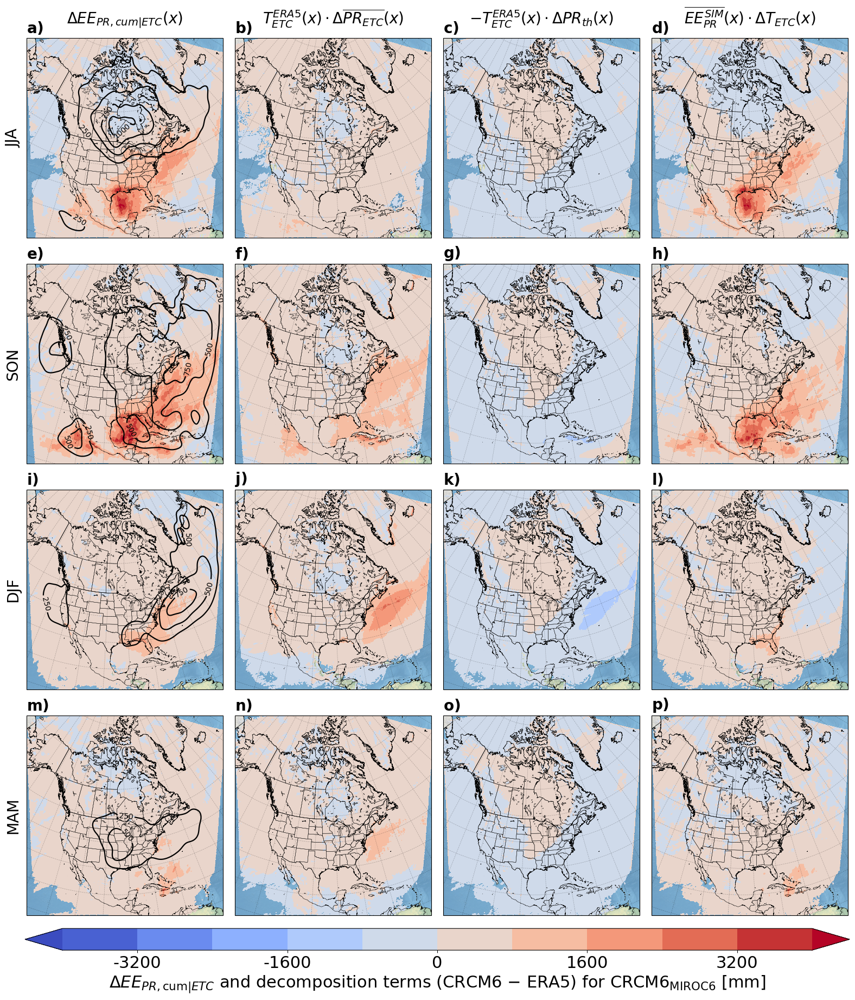

In [18]:
sim = [s for s in simulations if s != 'ERA5'][3]

term_total = {}
term1 = {}
term2 = {}
term3 = {}
cont_total = {}
cont_terms = {}
contour_levels_term_total = {}
contour_levels_terms = {}

steps_term_total = {'UBB': 250, 'UBD': 250, 'UBE': 250, 'UBF': 250}
steps_terms = {'UBB': 350, 'UBD': 600, 'UBE': 500, 'UBF': 900}

for season in ['JJA', 'SON', 'DJF', 'MAM']:
    total_era5 = data['total_ext_EETCs_seasonal']['ERA5'].sel(season=season, quantile=0.99, variable='pr')
    percentile_era5 = per_regridded['ERA5', 'pr'].sel(quantile=0.99).pr
    count_era5 = data['count_ext_EETCs_seasonal']['ERA5'].sel(season=season, quantile=0.99, variable='pr')
    EEcum_era5 = total_era5 - percentile_era5 * count_era5

    total_sim = data['total_ext_EETCs_seasonal'][sim].sel(season=season, quantile=0.99, variable='pr')
    percentile_sim = per_regridded[sim, 'pr'].sel(quantile=0.99).pr
    count_sim = data['count_ext_EETCs_seasonal'][sim].sel(season=season, quantile=0.99, variable='pr')
    EEcum_sim = total_sim - (percentile_sim * count_sim)

    diff = EEcum_sim.fillna(0) - EEcum_era5.fillna(0)
    term_total[season] = diff.where((np.abs(EEcum_sim) > 0.) | (np.abs(EEcum_era5) > 0.))

    mean_sim = total_sim / count_sim
    mean_era5 = total_era5 / count_era5
    term1[season] = count_era5.fillna(0) * (mean_sim.fillna(0) - mean_era5.fillna(0))
    term2[season] = count_era5.fillna(0) * (percentile_era5.fillna(0) - percentile_sim.fillna(0))

    mean_sim_exc = (total_sim - percentile_sim * count_sim) / count_sim.where(count_sim > 0)
    term3[season] = mean_sim_exc.fillna(0) * (count_sim.fillna(0) - count_era5.fillna(0))

    active_points = (count_sim > 0) | (count_era5 > 0)
    term1[season] = term1[season].where(active_points)
    term2[season] = term2[season].where(active_points)
    term3[season] = term3[season].where(active_points)

    cont_total[season] = EEcum_era5.where(EEcum_era5 > 0.)
    cont_terms[season] = term_total[season]

    contour_levels_term_total[season] = np.arange(
        -np.ceil(12000/steps_term_total[sim])*steps_term_total[sim],
        np.ceil(12000/steps_term_total[sim])*steps_term_total[sim] + steps_term_total[sim],
        steps_term_total[sim]
    )
    contour_levels_terms[season] = np.arange(
        -np.ceil(10000/steps_terms[sim])*steps_terms[sim],
        np.ceil(10000/steps_terms[sim])*steps_terms[sim] + steps_terms[sim],
        steps_terms[sim]
    )

plot_map_four_per_four_seasonal(
    [term_total, term1, term2, term3],
    cont=[cont_total],
    contour_levels=[contour_levels_term_total],
    sigma=7,
    colormap='coolwarm',
    vmin=-4000,
    vmax=4000,
    step=800,
    label=rf"$\Delta EE_{{PR,\mathrm{{cum}}|ETC}}$ and decomposition terms (CRCM6 $-$ ERA5) for {sim_label_nobold[sim]} [mm]",
    style='contourf'
)

plt.savefig(f"/home/vdemeyer/projects/rrg-gachon/vdemeyer/ALL/PLOT/supp_seasonal_CRCM6_MIROC6_PR_hist_vs_ERA5{tc_tag}.png", dpi=300, bbox_inches="tight")

### Surface Wind

#### UBB

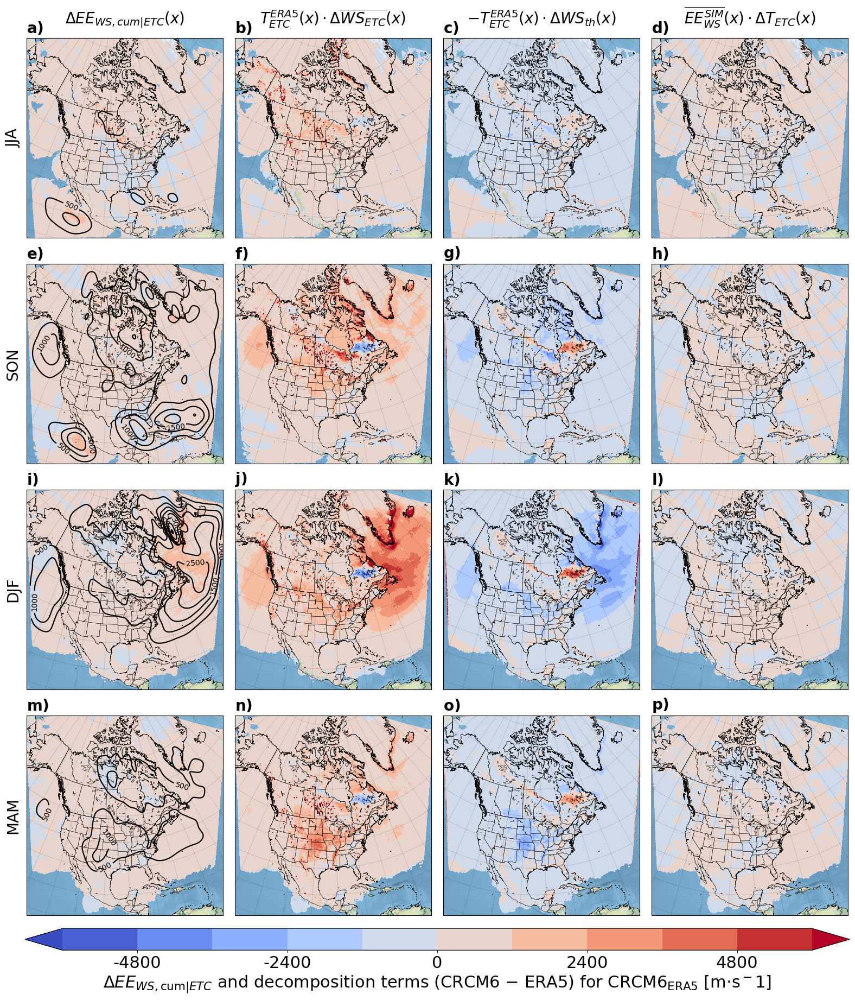

In [8]:
sim = [s for s in simulations if s != 'ERA5'][0]

term_total = {}
term1 = {}
term2 = {}
term3 = {}
cont_total = {}
cont_terms = {}
contour_levels_term_total = {}
contour_levels_terms = {}

steps_term_total = {'UBB': 500, 'UBD': 500, 'UBE': 500, 'UBF': 500}
steps_terms = {'UBB': 500, 'UBD': 800, 'UBE': 500, 'UBF': 1000}

for season in ['JJA', 'SON', 'DJF', 'MAM']:
    total_era5 = data['total_ext_EETCs_seasonal']['ERA5'].sel(season=season, quantile=0.99, variable='ws')
    percentile_era5 = per_regridded['ERA5', 'ws'].sel(quantile=0.99).surf_wind
    count_era5 = data['count_ext_EETCs_seasonal']['ERA5'].sel(season=season, quantile=0.99, variable='ws')
    EEcum_era5 = total_era5 - percentile_era5 * count_era5

    total_sim = data['total_ext_EETCs_seasonal'][sim].sel(season=season, quantile=0.99, variable='ws')
    percentile_sim = per_regridded[sim, 'ws'].sel(quantile=0.99).surf_wind
    count_sim = data['count_ext_EETCs_seasonal'][sim].sel(season=season, quantile=0.99, variable='ws')
    EEcum_sim = total_sim - (percentile_sim * count_sim)

    diff = EEcum_sim.fillna(0) - EEcum_era5.fillna(0)
    term_total[season] = diff.where((np.abs(EEcum_sim) > 0.) | (np.abs(EEcum_era5) > 0.))

    mean_sim = total_sim / count_sim
    mean_era5 = total_era5 / count_era5
    term1[season] = count_era5.fillna(0) * (mean_sim.fillna(0) - mean_era5.fillna(0))
    term2[season] = count_era5.fillna(0) * (percentile_era5.fillna(0) - percentile_sim.fillna(0))

    mean_sim_exc = (total_sim - percentile_sim * count_sim) / count_sim.where(count_sim > 0)
    term3[season] = mean_sim_exc.fillna(0) * (count_sim.fillna(0) - count_era5.fillna(0))

    active_points = (count_sim > 0) | (count_era5 > 0)
    term1[season] = term1[season].where(active_points)
    term2[season] = term2[season].where(active_points)
    term3[season] = term3[season].where(active_points)

    cont_total[season] = EEcum_era5.where(EEcum_era5 > 0.)
    cont_terms[season] = term_total[season]

    contour_levels_term_total[season] = np.arange(
        -np.ceil(12000/steps_term_total[sim])*steps_term_total[sim],
        np.ceil(12000/steps_term_total[sim])*steps_term_total[sim] + steps_term_total[sim],
        steps_term_total[sim]
    )
    contour_levels_terms[season] = np.arange(
        -np.ceil(10000/steps_terms[sim])*steps_terms[sim],
        np.ceil(10000/steps_terms[sim])*steps_terms[sim] + steps_terms[sim],
        steps_terms[sim]
    )

plot_map_four_per_four_seasonal(
    [term_total, term1, term2, term3],
    cont=[cont_total],
    contour_levels=[contour_levels_term_total],
    sigma=7,
    colormap='coolwarm',
    vmin=-6000,
    vmax=6000,
    step=1200,
    label=rf"$\Delta EE_{{WS,\mathrm{{cum}}|ETC}}$ and decomposition terms (CRCM6 $-$ ERA5) for {sim_label_nobold[sim]} [m$\cdot$s$^{-1}$]",
    style='contourf'
)

plt.savefig(f"/home/vdemeyer/projects/rrg-gachon/vdemeyer/ALL/PLOT/supp_seasonal_CRCM6_ERA5_WS_hist_vs_ERA5{tc_tag}.png", dpi=300, bbox_inches="tight")

#### UBD

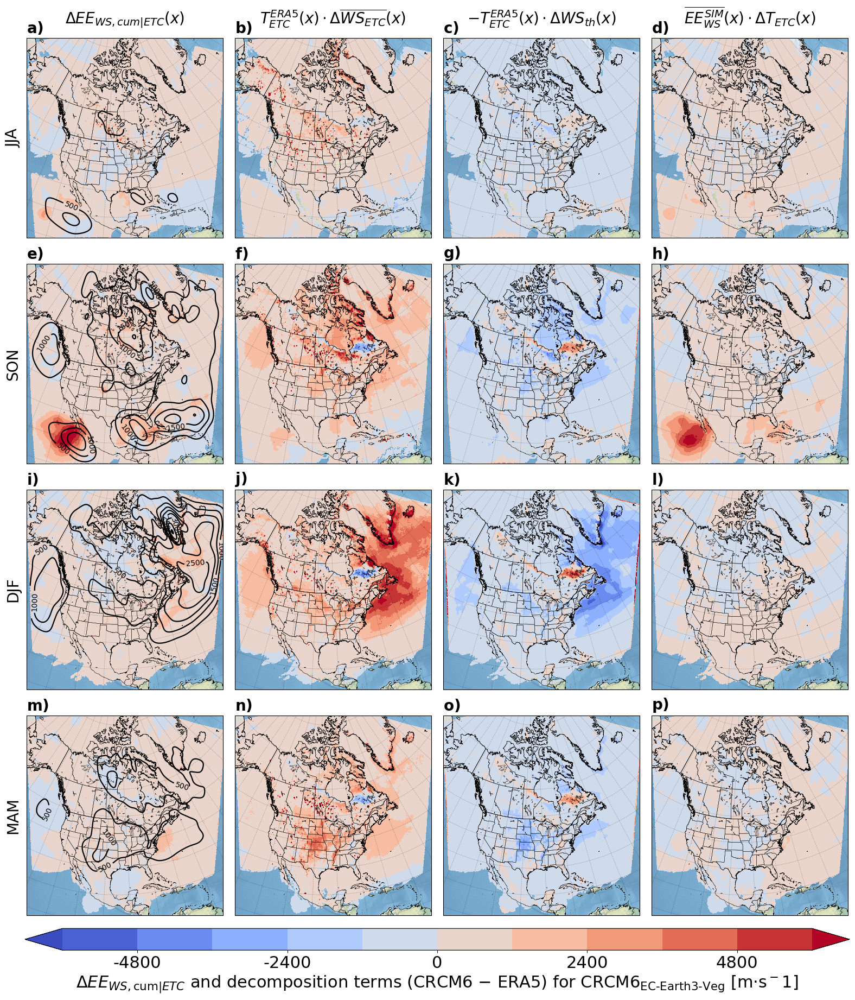

In [9]:
sim = [s for s in simulations if s != 'ERA5'][1]

term_total = {}
term1 = {}
term2 = {}
term3 = {}
cont_total = {}
cont_terms = {}
contour_levels_term_total = {}
contour_levels_terms = {}

steps_term_total = {'UBB': 500, 'UBD': 500, 'UBE': 500, 'UBF': 500}
steps_terms = {'UBB': 500, 'UBD': 800, 'UBE': 500, 'UBF': 1000}

for season in ['JJA', 'SON', 'DJF', 'MAM']:
    total_era5 = data['total_ext_EETCs_seasonal']['ERA5'].sel(season=season, quantile=0.99, variable='ws')
    percentile_era5 = per_regridded['ERA5', 'ws'].sel(quantile=0.99).surf_wind
    count_era5 = data['count_ext_EETCs_seasonal']['ERA5'].sel(season=season, quantile=0.99, variable='ws')
    EEcum_era5 = total_era5 - percentile_era5 * count_era5

    total_sim = data['total_ext_EETCs_seasonal'][sim].sel(season=season, quantile=0.99, variable='ws')
    percentile_sim = per_regridded[sim, 'ws'].sel(quantile=0.99).surf_wind
    count_sim = data['count_ext_EETCs_seasonal'][sim].sel(season=season, quantile=0.99, variable='ws')
    EEcum_sim = total_sim - (percentile_sim * count_sim)

    diff = EEcum_sim.fillna(0) - EEcum_era5.fillna(0)
    term_total[season] = diff.where((np.abs(EEcum_sim) > 0.) | (np.abs(EEcum_era5) > 0.))

    mean_sim = total_sim / count_sim
    mean_era5 = total_era5 / count_era5
    term1[season] = count_era5.fillna(0) * (mean_sim.fillna(0) - mean_era5.fillna(0))
    term2[season] = count_era5.fillna(0) * (percentile_era5.fillna(0) - percentile_sim.fillna(0))

    mean_sim_exc = (total_sim - percentile_sim * count_sim) / count_sim.where(count_sim > 0)
    term3[season] = mean_sim_exc.fillna(0) * (count_sim.fillna(0) - count_era5.fillna(0))

    active_points = (count_sim > 0) | (count_era5 > 0)
    term1[season] = term1[season].where(active_points)
    term2[season] = term2[season].where(active_points)
    term3[season] = term3[season].where(active_points)

    cont_total[season] = EEcum_era5.where(EEcum_era5 > 0.)
    cont_terms[season] = term_total[season]

    contour_levels_term_total[season] = np.arange(
        -np.ceil(12000/steps_term_total[sim])*steps_term_total[sim],
        np.ceil(12000/steps_term_total[sim])*steps_term_total[sim] + steps_term_total[sim],
        steps_term_total[sim]
    )
    contour_levels_terms[season] = np.arange(
        -np.ceil(10000/steps_terms[sim])*steps_terms[sim],
        np.ceil(10000/steps_terms[sim])*steps_terms[sim] + steps_terms[sim],
        steps_terms[sim]
    )

plot_map_four_per_four_seasonal(
    [term_total, term1, term2, term3],
    cont=[cont_total],
    contour_levels=[contour_levels_term_total],
    sigma=7,
    colormap='coolwarm',
    vmin=-6000,
    vmax=6000,
    step=1200,
    label=rf"$\Delta EE_{{WS,\mathrm{{cum}}|ETC}}$ and decomposition terms (CRCM6 $-$ ERA5) for {sim_label_nobold[sim]} [m$\cdot$s$^{-1}$]",
    style='contourf'
)

plt.savefig(f"/home/vdemeyer/projects/rrg-gachon/vdemeyer/ALL/PLOT/supp_seasonal_CRCM6_EC-Earth3-Veg_WS_hist_vs_ERA5{tc_tag}.png", dpi=300, bbox_inches="tight")

#### UBE

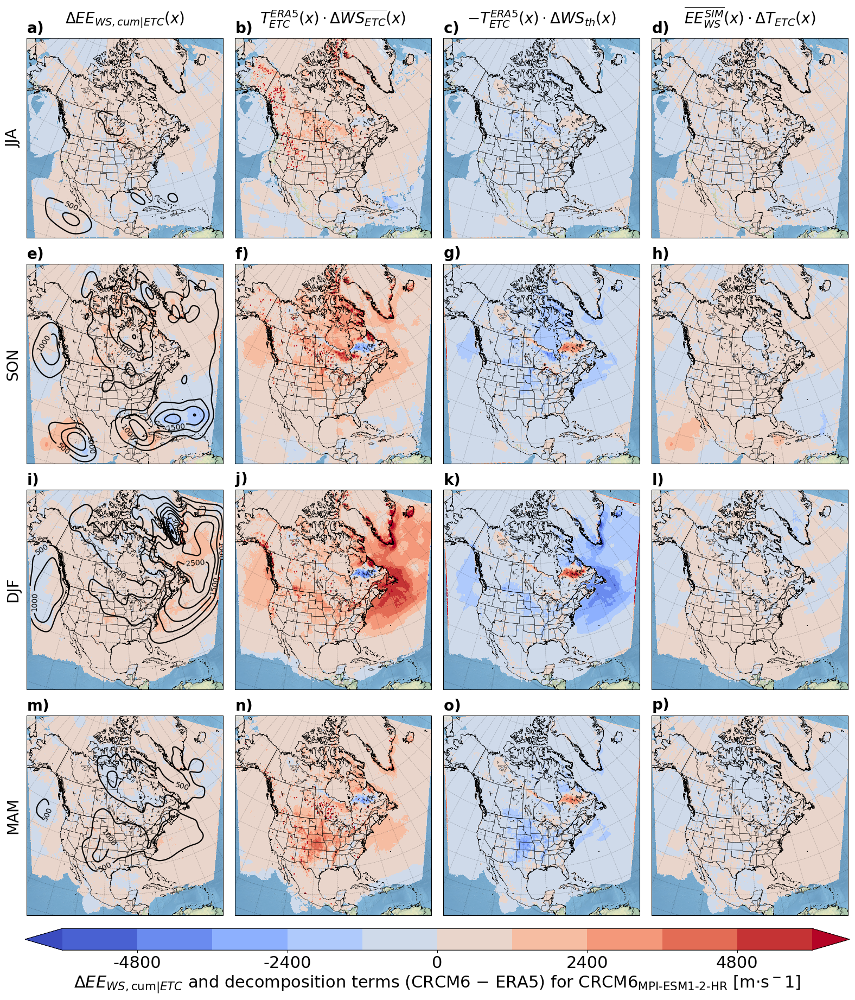

In [10]:
sim = [s for s in simulations if s != 'ERA5'][2]

term_total = {}
term1 = {}
term2 = {}
term3 = {}
cont_total = {}
cont_terms = {}
contour_levels_term_total = {}
contour_levels_terms = {}

steps_term_total = {'UBB': 500, 'UBD': 500, 'UBE': 500, 'UBF': 500}
steps_terms = {'UBB': 500, 'UBD': 800, 'UBE': 500, 'UBF': 1000}

for season in ['JJA', 'SON', 'DJF', 'MAM']:
    total_era5 = data['total_ext_EETCs_seasonal']['ERA5'].sel(season=season, quantile=0.99, variable='ws')
    percentile_era5 = per_regridded['ERA5', 'ws'].sel(quantile=0.99).surf_wind
    count_era5 = data['count_ext_EETCs_seasonal']['ERA5'].sel(season=season, quantile=0.99, variable='ws')
    EEcum_era5 = total_era5 - percentile_era5 * count_era5

    total_sim = data['total_ext_EETCs_seasonal'][sim].sel(season=season, quantile=0.99, variable='ws')
    percentile_sim = per_regridded[sim, 'ws'].sel(quantile=0.99).surf_wind
    count_sim = data['count_ext_EETCs_seasonal'][sim].sel(season=season, quantile=0.99, variable='ws')
    EEcum_sim = total_sim - (percentile_sim * count_sim)

    diff = EEcum_sim.fillna(0) - EEcum_era5.fillna(0)
    term_total[season] = diff.where((np.abs(EEcum_sim) > 0.) | (np.abs(EEcum_era5) > 0.))

    mean_sim = total_sim / count_sim
    mean_era5 = total_era5 / count_era5
    term1[season] = count_era5.fillna(0) * (mean_sim.fillna(0) - mean_era5.fillna(0))
    term2[season] = count_era5.fillna(0) * (percentile_era5.fillna(0) - percentile_sim.fillna(0))

    mean_sim_exc = (total_sim - percentile_sim * count_sim) / count_sim.where(count_sim > 0)
    term3[season] = mean_sim_exc.fillna(0) * (count_sim.fillna(0) - count_era5.fillna(0))

    active_points = (count_sim > 0) | (count_era5 > 0)
    term1[season] = term1[season].where(active_points)
    term2[season] = term2[season].where(active_points)
    term3[season] = term3[season].where(active_points)

    cont_total[season] = EEcum_era5.where(EEcum_era5 > 0.)
    cont_terms[season] = term_total[season]

    contour_levels_term_total[season] = np.arange(
        -np.ceil(12000/steps_term_total[sim])*steps_term_total[sim],
        np.ceil(12000/steps_term_total[sim])*steps_term_total[sim] + steps_term_total[sim],
        steps_term_total[sim]
    )
    contour_levels_terms[season] = np.arange(
        -np.ceil(10000/steps_terms[sim])*steps_terms[sim],
        np.ceil(10000/steps_terms[sim])*steps_terms[sim] + steps_terms[sim],
        steps_terms[sim]
    )

plot_map_four_per_four_seasonal(
    [term_total, term1, term2, term3],
    cont=[cont_total],
    contour_levels=[contour_levels_term_total],
    sigma=7,
    colormap='coolwarm',
    vmin=-6000,
    vmax=6000,
    step=1200,
    label=rf"$\Delta EE_{{WS,\mathrm{{cum}}|ETC}}$ and decomposition terms (CRCM6 $-$ ERA5) for {sim_label_nobold[sim]} [m$\cdot$s$^{-1}$]",
    style='contourf'
)

plt.savefig(f"/home/vdemeyer/projects/rrg-gachon/vdemeyer/ALL/PLOT/supp_seasonal_CRCM6_MPI-ESM1-2-HR_WS_hist_vs_ERA5{tc_tag}.png", dpi=300, bbox_inches="tight")

#### UBF

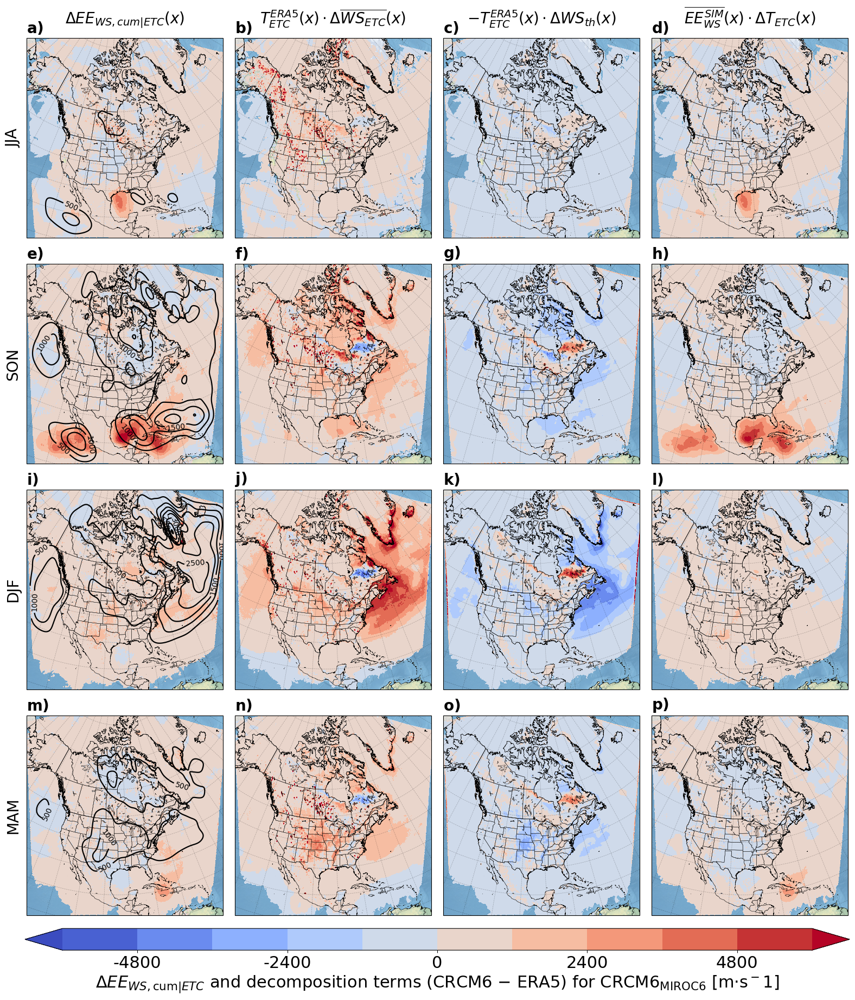

In [11]:
sim = [s for s in simulations if s != 'ERA5'][3]

term_total = {}
term1 = {}
term2 = {}
term3 = {}
cont_total = {}
cont_terms = {}
contour_levels_term_total = {}
contour_levels_terms = {}

steps_term_total = {'UBB': 500, 'UBD': 500, 'UBE': 500, 'UBF': 500}
steps_terms = {'UBB': 500, 'UBD': 800, 'UBE': 500, 'UBF': 1000}

for season in ['JJA', 'SON', 'DJF', 'MAM']:
    total_era5 = data['total_ext_EETCs_seasonal']['ERA5'].sel(season=season, quantile=0.99, variable='ws')
    percentile_era5 = per_regridded['ERA5', 'ws'].sel(quantile=0.99).surf_wind
    count_era5 = data['count_ext_EETCs_seasonal']['ERA5'].sel(season=season, quantile=0.99, variable='ws')
    EEcum_era5 = total_era5 - percentile_era5 * count_era5

    total_sim = data['total_ext_EETCs_seasonal'][sim].sel(season=season, quantile=0.99, variable='ws')
    percentile_sim = per_regridded[sim, 'ws'].sel(quantile=0.99).surf_wind
    count_sim = data['count_ext_EETCs_seasonal'][sim].sel(season=season, quantile=0.99, variable='ws')
    EEcum_sim = total_sim - (percentile_sim * count_sim)

    diff = EEcum_sim.fillna(0) - EEcum_era5.fillna(0)
    term_total[season] = diff.where((np.abs(EEcum_sim) > 0.) | (np.abs(EEcum_era5) > 0.))

    mean_sim = total_sim / count_sim
    mean_era5 = total_era5 / count_era5
    term1[season] = count_era5.fillna(0) * (mean_sim.fillna(0) - mean_era5.fillna(0))
    term2[season] = count_era5.fillna(0) * (percentile_era5.fillna(0) - percentile_sim.fillna(0))

    mean_sim_exc = (total_sim - percentile_sim * count_sim) / count_sim.where(count_sim > 0)
    term3[season] = mean_sim_exc.fillna(0) * (count_sim.fillna(0) - count_era5.fillna(0))

    active_points = (count_sim > 0) | (count_era5 > 0)
    term1[season] = term1[season].where(active_points)
    term2[season] = term2[season].where(active_points)
    term3[season] = term3[season].where(active_points)

    cont_total[season] = EEcum_era5.where(EEcum_era5 > 0.)
    cont_terms[season] = term_total[season]

    contour_levels_term_total[season] = np.arange(
        -np.ceil(12000/steps_term_total[sim])*steps_term_total[sim],
        np.ceil(12000/steps_term_total[sim])*steps_term_total[sim] + steps_term_total[sim],
        steps_term_total[sim]
    )
    contour_levels_terms[season] = np.arange(
        -np.ceil(10000/steps_terms[sim])*steps_terms[sim],
        np.ceil(10000/steps_terms[sim])*steps_terms[sim] + steps_terms[sim],
        steps_terms[sim]
    )

plot_map_four_per_four_seasonal(
    [term_total, term1, term2, term3],
    cont=[cont_total],
    contour_levels=[contour_levels_term_total],
    sigma=7,
    colormap='coolwarm',
    vmin=-6000,
    vmax=6000,
    step=1200,
    label=rf"$\Delta EE_{{WS,\mathrm{{cum}}|ETC}}$ and decomposition terms (CRCM6 $-$ ERA5) for {sim_label_nobold[sim]} [m$\cdot$s$^{-1}$]",
    style='contourf'
)

plt.savefig(f"/home/vdemeyer/projects/rrg-gachon/vdemeyer/ALL/PLOT/supp_seasonal_CRCM6_MIROC6_WS_hist_vs_ERA5{tc_tag}.png", dpi=300, bbox_inches="tight")

## For testing the template

In [ ]:
positions = [
    [0.05, 0.48, 0.29, 0.50],  # Rangée du haut, Colonne 1
    [0.35, 0.48, 0.29, 0.50],  # Rangée du haut, Colonne 2
    [0.65, 0.48, 0.29, 0.50],  # Rangée du haut, Colonne 3
    [0.05, 0.15, 0.29, 0.50],  # Rangée du bas, Colonne 1
    [0.35, 0.15, 0.29, 0.50],  # Rangée du bas, Colonne 2
    # Le sixième emplacement [0.65, 0.11, 0.29, 0.50] est ignoré comme dans le code original
]

sim_label = [
    r'ERA5',
    r'CRCM6$_{\mathbf{ERA5}}$',
    r'CRCM6$_{\mathbf{EC\text{-}Earth3\text{-}Veg}}$',
    r'CRCM6$_{\mathbf{MPI\text{-}ESM1\text{-}2\text{-}HR}}$',
    r'CRCM6$_{\mathbf{MIROC6}}$'
]

lon = np.linspace(-80, -50, 10)
lat = np.linspace(40, 60, 10)
lon2d, lat2d = np.meshgrid(lon, lat)

# Data aléatoire
dummy_data = np.random.uniform(0, 10, size=(10, 10))
dummy_data_2 = np.random.uniform(-10, 10, size=(10, 10))

plotcrs = ccrs.LambertConformal(central_latitude=45, central_longitude=-95)
fig = plt.figure(figsize=(15, 15))
axes = [fig.add_axes(pos, projection=plotcrs) for pos in positions]

for i, ax in enumerate(axes):
    
    crs = ccrs.PlateCarree()

    # ax.set_extent([-130, -51, 77, 13], crs=ccrs.PlateCarree())
    ax.set_extent([-128, -56, 81, 12], crs=ccrs.PlateCarree())
    ax.coastlines(resolution='10m', linewidth=0.4, color='black')
    
    ax.text(0.02, 0.98, sim_label[i], transform=ax.transAxes, fontsize=21, fontweight='bold',
            ha='left', va='top', bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', boxstyle='round,pad=0.2'))

    sc_era5 = ax.contourf(
        lon2d, lat2d, dummy_data,
        levels=np.arange(0,12,2.5),
        cmap='Spectral_r', vmin=0, vmax=10, extend='max'
    )

    sc_sim = ax.contourf(
        lon2d, lat2d, dummy_data_2,
        levels=np.arange(-10,10.5,5),
        cmap='coolwarm', vmin=-10, vmax=10, extend='both'
    )
    
    letter = f"$\\mathbf{{{chr(97+i)})}}$"
    ax.text(
        0, 1.02,
        letter,
        transform=ax.transAxes,
        fontsize=22,
        ha='left',
        va='bottom'
    )

left_min = min(pos[0] for pos in positions)
left_max = max(pos[0] + pos[2] for pos in positions)
cbar_ax1 = fig.add_axes([left_min, 0.22, left_max - left_min, 0.018])
cbar_ax2 = fig.add_axes([left_min, 0.14, left_max - left_min, 0.018])

cbar1 = fig.colorbar(sc_era5, cax=cbar_ax1, orientation="horizontal", pad=0.02)
cbar1.set_label('ETST', fontsize=22)
cbar1.ax.tick_params(labelsize=22)

cbar2 = fig.colorbar(sc_sim, cax=cbar_ax2, orientation="horizontal", pad=0.02)
cbar2.set_label('TEST', fontsize=22)
cbar2.ax.tick_params(labelsize=22)

In [ ]:
positions = [
    [0.08, 0.48, 0.42, 0.50],  # Haut gauche
    [0.52, 0.48, 0.42, 0.50],  # Haut droite
    [0.08, 0.15, 0.42, 0.50],  # Bas gauche
    [0.52, 0.15, 0.42, 0.50],  # Bas droite
]

sim_label = [
    # r'ERA5',
    r'CRCM6$_{\mathbf{ERA5}}$',
    r'CRCM6$_{\mathbf{EC\text{-}Earth3\text{-}Veg}}$',
    r'CRCM6$_{\mathbf{MPI\text{-}ESM1\text{-}2\text{-}HR}}$',
    r'CRCM6$_{\mathbf{MIROC6}}$'
]

lon = np.linspace(-80, -50, 10)
lat = np.linspace(40, 60, 10)
lon2d, lat2d = np.meshgrid(lon, lat)

# Data aléatoire
dummy_data = np.random.uniform(0, 10, size=(10, 10))
dummy_data_2 = np.random.uniform(-10, 10, size=(10, 10))

plotcrs = ccrs.LambertConformal(central_latitude=45, central_longitude=-95)
fig = plt.figure(figsize=(10, 15))
axes = [fig.add_axes(pos, projection=plotcrs) for pos in positions]

for i, ax in enumerate(axes):
    
    crs = ccrs.PlateCarree()

    ax.set_extent([-128, -56, 81, 12], crs=ccrs.PlateCarree())
    ax.coastlines(resolution='10m', linewidth=0.4, color='black')

    sc = ax.contourf(
        lon2d, lat2d, dummy_data,
        levels=np.arange(0,12,2.5),
        cmap='Spectral_r', vmin=0, vmax=10, extend='max'
    )
    
    ax.text(0.02, 0.98, sim_label[i], transform=ax.transAxes, fontsize=17, fontweight='bold',
            ha='left', va='top', bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', boxstyle='round,pad=0.2'))
    
    letter = f"$\\mathbf{{{chr(97+i)})}}$"
    ax.text(0, 1.02, letter, transform=ax.transAxes, fontsize=21, ha='left', va='bottom')

left_min = min(pos[0] for pos in positions)
left_max = max(pos[0] + pos[2] for pos in positions)
cbar_ax = fig.add_axes([left_min, 0.215, left_max - left_min, 0.025])

cbar = fig.colorbar(sc, cax=cbar_ax, orientation="horizontal", pad=0.001)
cbar.set_label('Difference in Precipitation Accumulated\nExtreme Exceedance (CRCM6 - ERA5) [mm]', fontsize=18)
cbar.ax.tick_params(labelsize=18)

In [ ]:
# --------- PARAMÈTRES FACILES À MODIFIER ----------
ncols = 3
nrows = 4

left_margin   = 0.06
right_margin  = 0.04
top_margin    = 0.04
bottom_margin = 0.06

hspace = 0.03   # espace vertical entre les lignes
wspace = 0.015   # espace horizontal entre les colonnes
# ---------------------------------------------------

# Largeur/hauteur disponible
usable_width  = 1 - left_margin - right_margin
usable_height = 1 - top_margin - bottom_margin

# Taille de chaque subplot
ax_width  = (usable_width  - (ncols - 1) * wspace) / ncols
ax_height = (usable_height - (nrows - 1) * hspace) / nrows

# Génération automatique des positions
positions = []
for row in range(nrows):
    for col in range(ncols):
        left = left_margin + col * (ax_width + wspace)
        bottom = 1 - top_margin - (row + 1) * ax_height - row * hspace
        positions.append([left, bottom, ax_width, ax_height])
        
        
sim_label = [
    # r'ERA5',
    r'CRCM6$_{\mathbf{ERA5}}$',
    r'CRCM6$_{\mathbf{EC\text{-}Earth3\text{-}Veg}}$',
    r'CRCM6$_{\mathbf{MPI\text{-}ESM1\text{-}2\text{-}HR}}$',
    r'CRCM6$_{\mathbf{MIROC6}}$'
]

lon = np.linspace(-80, -50, 10)
lat = np.linspace(40, 60, 10)
lon2d, lat2d = np.meshgrid(lon, lat)

# Data aléatoire
dummy_data = np.random.uniform(0, 10, size=(10, 10))
dummy_data_2 = np.random.uniform(-10, 10, size=(10, 10))

plotcrs = ccrs.LambertConformal(central_latitude=45, central_longitude=-95)
fig = plt.figure(figsize=(15, 22))
axes = [fig.add_axes(pos, projection=plotcrs) for pos in positions]
crs = ccrs.PlateCarree()

for i, ax in enumerate(axes):
    
    # ax.set_extent([-130, -51, 77, 13], crs=ccrs.PlateCarree())
    ax.set_extent([-128, -56, 81, 12], crs=ccrs.PlateCarree())
    ax.coastlines(resolution='10m', linewidth=0.4, color='black')
    
    label = sim_label[i // 3]
    
    ax.text(0.02, 0.98, label,
            transform=ax.transAxes, fontsize=21, fontweight='bold',
            ha='left', va='top',
            bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', boxstyle='round,pad=0.2'))

    sc = ax.contourf(
        lon2d, lat2d, dummy_data,
        levels=np.arange(0,12,2.5),
        cmap='Spectral_r', vmin=0, vmax=10, extend='max'
    )
    
    letter = f"$\\mathbf{{{chr(97+i)})}}$"
    ax.text(
        0, 1.02,
        letter,
        transform=ax.transAxes,
        fontsize=22,
        ha='left',
        va='bottom'
    )

left_min = min(pos[0] for pos in positions)
left_max = max(pos[0] + pos[2] for pos in positions)
cbar_ax = fig.add_axes([left_min, 0.02, left_max - left_min, 0.02])

cbar = fig.colorbar(sc, cax=cbar_ax, orientation="horizontal", pad=0.02)
cbar.set_label('ETST', fontsize=22)
cbar.ax.tick_params(labelsize=22)

In [ ]:
term_labels = [
    r'$T_{ETC}^{ERA5}(x) \cdot \Delta \overline{V_{ETC}}(x)$',
    r'$- T_{ETC}^{ERA5}(x) \cdot \Delta V_{th}(x)$',
    r'$\overline{EE_{V}^{SIM}}(x) \cdot \Delta T_{ETC}(x)$'
]

sim_label = [
    r'CRCM6$_{\mathbf{ERA5}}$',
    r'CRCM6$_{\mathbf{EC\text{-}Earth3\text{-}Veg}}$',
    r'CRCM6$_{\mathbf{MPI\text{-}ESM1\text{-}2\text{-}HR}}$',
    r'CRCM6$_{\mathbf{MIROC6}}$'
]

plotcrs = ccrs.LambertConformal(central_latitude=45, central_longitude=-95)
fig = plt.figure(figsize=(15, 22))
axes = [fig.add_axes(pos, projection=plotcrs) for pos in positions]
crs = ccrs.PlateCarree()

# Ajout titres de colonnes (termes)
for col in range(ncols):
    # Centrer au-dessus de la colonne
    left = positions[col][0] + ax_width/2
    top = 1 - top_margin + 0.01  # juste au-dessus du top margin
    fig.text(left, top, term_labels[col], ha='center', va='bottom', fontsize=20, fontweight='bold')

# Ajout titres de lignes (modèles), vertical à gauche
for row in range(nrows):
    # Prendre la première colonne de chaque ligne
    left = left_margin - 0.01  # juste à gauche du plot
    bottom = positions[row*ncols][1] + ax_height/2
    fig.text(left, bottom, sim_label[row], ha='right', va='center', fontsize=20, fontweight='bold', rotation=90)

# Boucle sur les axes
for i, ax in enumerate(axes):
    ax.set_extent([-128, -56, 81, 12], crs=ccrs.PlateCarree())
    ax.coastlines(resolution='10m', linewidth=0.4, color='black')

    sc = ax.contourf(
        lon2d, lat2d, dummy_data,
        levels=np.arange(0,12,2.5),
        cmap='Spectral_r', vmin=0, vmax=10, extend='max'
    )

    letter = f"$\\mathbf{{{chr(97+i)})}}$"
    ax.text(0, 1.02, letter, transform=ax.transAxes, fontsize=22, ha='left', va='bottom')

# Colorbar horizontale
left_min = min(pos[0] for pos in positions)
left_max = max(pos[0] + pos[2] for pos in positions)
cbar_ax = fig.add_axes([left_min, 0.02, left_max - left_min, 0.02])
cbar = fig.colorbar(sc, cax=cbar_ax, orientation="horizontal", pad=0.02)
cbar.set_label('ETST', fontsize=22)
cbar.ax.tick_params(labelsize=22)

In [ ]:
ncols = 4
nrows = 4

positions = [
    # Ligne 1
    [0.0,  0.83, 0.23, 0.23],
    [0.24, 0.83, 0.23, 0.23],
    [0.48, 0.83, 0.23, 0.23],
    [0.72, 0.83, 0.23, 0.23],
    
    # Ligne 2
    [0.0,  0.57, 0.23, 0.23],
    [0.24, 0.57, 0.23, 0.23],
    [0.48, 0.57, 0.23, 0.23],
    [0.72, 0.57, 0.23, 0.23],

    # Ligne 3
    [0.0,  0.31, 0.23, 0.23],
    [0.24, 0.31, 0.23, 0.23],
    [0.48, 0.31, 0.23, 0.23],
    [0.72, 0.31, 0.23, 0.23],

    # Ligne 4
    [0.0,  0.05, 0.23, 0.23],
    [0.24, 0.05, 0.23, 0.23],
    [0.48, 0.05, 0.23, 0.23],
    [0.72, 0.05, 0.23, 0.23],
]

ax_width  = positions[0][2]
ax_height = positions[0][3]
left_margin = min(p[0] for p in positions)
bottom_margin = min(p[1] for p in positions)
top_margin = 1 - max(p[1] + p[3] for p in positions)
right_margin = 1 - max(p[0] + p[2] for p in positions)
        
var_label = 'PR'
term_labels = [
    r"$\Delta EE_{" + var_label + ",cum|ETC}(x)$",
    r"$T_{ETC}^{ERA5}(x) \cdot \Delta \overline{" + var_label + "_{ETC}}(x)$",
    r"$- T_{ETC}^{ERA5}(x) \cdot \Delta {" + var_label + "}_{th}(x)$",
    r"$\overline{EE_{" + var_label + "}^{SIM}}(x) \cdot \Delta T_{ETC}(x)$"
]

sim_label = [
    r'CRCM6$_{\mathbf{ERA5}}$',
    r'CRCM6$_{\mathbf{EC\text{-}Earth3\text{-}Veg}}$',
    r'CRCM6$_{\mathbf{MPI\text{-}ESM1\text{-}2\text{-}HR}}$',
    r'CRCM6$_{\mathbf{MIROC6}}$'
]

lon = np.linspace(-80, -50, 10)
lat = np.linspace(40, 60, 10)
lon2d, lat2d = np.meshgrid(lon, lat)

# Data aléatoire
dummy_data = np.random.uniform(0, 10, size=(10, 10))
dummy_data_2 = np.random.uniform(-10, 10, size=(10, 10))

plotcrs = ccrs.LambertConformal(central_latitude=45, central_longitude=-95)
fig = plt.figure(figsize=(16, 16))
axes = [fig.add_axes(pos, projection=plotcrs) for pos in positions]
crs = ccrs.PlateCarree()

# Ajout titres de colonnes (termes)
for col in range(ncols):
    # Centrer au-dessus de la colonne
    left = positions[col][0] + ax_width/2
    top = 1 - top_margin + 0.01  # juste au-dessus du top margin
    fig.text(left, top, term_labels[col], ha='center', va='bottom', fontsize=20, fontweight='bold')

# Ajout titres de lignes (modèles), vertical à gauche
for row in range(nrows):
    # Prendre la première colonne de chaque ligne
    left = left_margin - 0.005  # juste à gauche du plot
    bottom = positions[row*ncols][1] + ax_height/2
    fig.text(left, bottom, sim_label[row], ha='right', va='center', fontsize=20, fontweight='bold', rotation=90)

# Boucle sur les axes
for i, ax in enumerate(axes):
    ax.set_extent([-128, -56, 81, 12], crs=ccrs.PlateCarree())
    ax.coastlines(resolution='10m', linewidth=0.4, color='black')
    sc = ax.contourf(
        lon2d, lat2d, dummy_data,
        levels=np.arange(0,12,2.5),
        cmap='Spectral_r', vmin=0, vmax=10, extend='max'
    )

    letter = f"$\\mathbf{{{chr(97+i)})}}$"
    ax.text(0, 1.02, letter, transform=ax.transAxes, fontsize=20, ha='left', va='bottom')

# Colorbar horizontale
left_min = min(pos[0] for pos in positions)
left_max = max(pos[0] + pos[2] for pos in positions)
cbar_ax = fig.add_axes([left_min, 0.01, left_max - left_min, 0.025])
cbar = fig.colorbar(sc, cax=cbar_ax, orientation="horizontal", pad=0.023)
cbar.set_label('ETST', fontsize=22)
cbar.ax.tick_params(labelsize=22)